# Milestone 2 - Estimasi Harga Mobil Bekas di Jerman dengan Machine Learning

**Nama:** Rizqi Yudha Utama
**Batch:** 046

### Dataset
- **Nama dataset:** Germany Used Cars Dataset 2023
- **Sumber:** https://www.kaggle.com/datasets/wspirat/germany-used-cars-dataset-2023 (data iklan dari AutoScout24)
- **Ukuran:** 251079 baris, 15 kolom
- **Gambaran isi:** Dataset berupa penjualan mobil bekas di Jerman dengan sumber data diambil dari website penjualan mobil bekas terbesar di Jerman yaitu AutoScout24

### Problem

Orang yang mau menjual mobil bekas sering bingung harus memasang harga berapa, karena harga mobil bekas dipengaruhi banyak hal, seperti merek, model, tahun, tenaga mesin, jarak tempuh, transmisi, dan jenis bahan bakar. Tanpa acuan, penjual hanya mengira-ngira, sehingga harga yang dipasang bisa jauh dari harga pasaran.

Pada tahun 2023, saat data ini diambil, harga mobil bekas di Jerman juga sedang tidak stabil. Menurut laporan AutoScout24, rata-rata harga mobil bekas mencapai rekor tertinggi di bulan Maret 2023, lalu terus turun hingga sekitar **€27.883** di bulan September. Di saat yang sama, stok mobil bekas di dealer naik sekitar **17%** dibanding tahun sebelumnya, dan harga mobil listrik bekas turun sekitar **€10.000** sejak awal tahun ([AutoScout24](https://www.autoscout24.de/unternehmen/daten/autoscout24-marktreport-fuer-das-dritte-quartal-umschwung-im-deutschen-gebrauchtwagenmarkt-setzt-sich-fort/)). Dengan harga pasar yang terus bergerak, penjual membutuhkan acuan harga berbasis data, bukan sekadar perkiraan.

Pada project ini dibangun **model machine learning (regresi)** yang dilatih dari data iklan mobil bekas di Jerman, untuk memberikan **estimasi harga pasaran yang wajar sebagai acuan awal** sebelum penjual memasang harga.

- Penjual bisa memakai estimasi ini sebagai titik awal menentukan harga iklan, lalu menyesuaikannya sendiri dengan kondisi mobil.
- Pembeli bisa memakai estimasi ini untuk membandingkan apakah harga sebuah iklan masih dalam kisaran wajar.
- Project ini hanya fokus memberikan estimasi harga pasaran dari data spesifikasi mobil, dan tidak memprediksi berapa lama mobil akan laku.

### Objective

- Membangun **model machine learning regresi** untuk mengestimasi harga iklan mobil bekas (`price_in_euro`) berdasarkan spesifikasi mobil, seperti merek, model, umur, jarak tempuh, tenaga mesin, transmisi, dan jenis bahan bakar.
- Membandingkan beberapa algoritma (Linear Regression, KNN, SVM, Decision Tree, Random Forest, dan Gradient Boosting) menggunakan **cross validation**, lalu melakukan **hyperparameter tuning** pada model terbaik.
- Mengevaluasi model dengan **MAE** sebagai metrik utama (rata-rata selisih tebakan dengan harga asli dalam euro), serta **RMSE** dan **R²** sebagai metrik pendukung.
- Menyediakan aplikasi sederhana (**deployment**) supaya pengguna bisa langsung mendapatkan estimasi harga dengan memasukkan data mobilnya.

### User

- **Penjual perorangan** yang mau menjual mobilnya sendiri, supaya tidak memasang harga terlalu jauh dari harga pasaran.

Pengguna memiliki data mobil seperti pada dataset aslinya (merek, model, warna, tahun, jarak tempuh, tenaga mesin, transmisi, jenis bahan bakar, dan konsumsi bahan bakar).


# 1. Import Libraries

In [ ]:
# Import Libraries

# library untuk mengolah data
import pandas as pd
import numpy as np

# library untuk visualisasi
import seaborn as sns
import matplotlib.pyplot as plt

# library untuk menyimpan model
import pickle
import os

# library scikit-learn untuk split data, cross validation, dan hyperparameter tuning
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV

# library scikit-learn untuk preprocessing dan pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

# library scikit-learn untuk model
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import LinearSVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# library scikit-learn untuk metrik evaluasi
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Loading Data

In [271]:
# loading data 

df_ori = pd.read_csv("dataset/data.csv")

In [272]:
df_ori

,Unnamed: 0,brand,model,color,registration_date,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km,offer_description
0,0,alfa-romeo,Alfa Romeo GTV,red,10/1995,1995,1300,148,201,Manual,Petrol,"10,9 l/100 km",260 g/km,160500.00,2.0 V6 TB
1,1,alfa-romeo,Alfa Romeo 164,black,02/1995,1995,24900,191,260,Manual,Petrol,NaN,- (g/km),190000.00,"Q4 Allrad, 3.2L GTA"
2,2,alfa-romeo,Alfa Romeo Spider,black,02/1995,1995,5900,110,150,Unknown,Petrol,NaN,- (g/km),129000.00,ALFA ROME 916
3,3,alfa-romeo,Alfa Romeo Spider,black,07/1995,1995,4900,110,150,Manual,Petrol,"9,5 l/100 km",225 g/km,189500.00,2.0 16V Twin Spark L
4,4,alfa-romeo,Alfa Romeo 164,red,11/1996,1996,17950,132,179,Manual,Petrol,"7,2 l/100 km",- (g/km),96127.00,"3.0i Super V6, absoluter Topzustand !"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251074,251074,volvo,Volvo XC40,white,04/2023,2023,57990,192,261,Automatic,Hybrid,NaN,43 km Reichweite,1229.00,Plus Bright T5 Recharge Intellisafe*Surround+P...
251075,251075,volvo,Volvo XC90,white,03/2023,2023,89690,173,235,Automatic,Diesel,"7,6 l/100 km",202 g/km,4900.00,B5 AWD Diesel Ultimate Dark 7-Sitzer Massage F...
251076,251076,volvo,Volvo V60,white,05/2023,2023,61521,145,197,Automatic,Diesel,"4,7 l/100 km",125 g/km,1531.00,"B4 D Plus Dark 145 kW, 5-türig (Diesel)"
251077,251077,volvo,Volvo XC40,white,05/2023,2023,57890,132,179,Automatic,Hybrid,NaN,45 km Reichweite,1500.00,T5 Recharge Plus Dark *Standh*360°*beh.Lenk


In [273]:
df_ori.shape

(251079, 15)

Terdapat `251.079` baris pada data dengan `15 kolom`

In [274]:
df_ori.head(10)

,Unnamed: 0,brand,model,color,registration_date,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km,offer_description
0,0,alfa-romeo,Alfa Romeo GTV,red,10/1995,1995,1300,148,201,Manual,Petrol,"10,9 l/100 km",260 g/km,160500.00,2.0 V6 TB
1,1,alfa-romeo,Alfa Romeo 164,black,02/1995,1995,24900,191,260,Manual,Petrol,NaN,- (g/km),190000.00,"Q4 Allrad, 3.2L GTA"
2,2,alfa-romeo,Alfa Romeo Spider,black,02/1995,1995,5900,110,150,Unknown,Petrol,NaN,- (g/km),129000.00,ALFA ROME 916
3,3,alfa-romeo,Alfa Romeo Spider,black,07/1995,1995,4900,110,150,Manual,Petrol,"9,5 l/100 km",225 g/km,189500.00,2.0 16V Twin Spark L
4,4,alfa-romeo,Alfa Romeo 164,red,11/1996,1996,17950,132,179,Manual,Petrol,"7,2 l/100 km",- (g/km),96127.00,"3.0i Super V6, absoluter Topzustand !"
5,5,alfa-romeo,Alfa Romeo Spider,red,04/1996,1996,7900,110,150,Manual,Petrol,"9,5 l/100 km",225 g/km,47307.00,2.0 16V Twin Spark
6,6,alfa-romeo,Alfa Romeo 145,red,12/1996,1996,3500,110,150,Manual,Petrol,"8,8 l/100 km",210 g/km,230000.00,Quadrifoglio
7,7,alfa-romeo,Alfa Romeo 164,black,07/1996,1996,5500,132,179,Manual,Petrol,"13,4 l/100 km",320 g/km,168000.00,(3.0) V6 Super
8,8,alfa-romeo,Alfa Romeo Spider,black,07/1996,1996,8990,141,192,Manual,Petrol,11 l/100 km,265 g/km,168600.00,|HU:neu|Klimaanlage|Youngtimer|
9,9,alfa-romeo,Alfa Romeo Spider,black,01/1996,1996,6976,110,150,Manual,Petrol,"9,2 l/100 km",220 g/km,99000.00,2.0 T.Spark L *Klima *2.Hand *Zahnriemen


In [275]:
df_ori.tail(10)

,Unnamed: 0,brand,model,color,registration_date,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km,offer_description
251069,251069,volvo,Volvo V90 Cross Country,silver,03/2023,2023,77900,173,235,Automatic,Diesel,"5,5 l/100 km",144 g/km,2500.00,B5 D AWD Geartronic ULTIMATE
251070,251070,volvo,Volvo V90 Cross Country,silver,01/2023,2023,65422,145,197,Automatic,Diesel,"6,5 l/100 km",170 g/km,1506.00,B4 DIESEL PLUS AWD MY23 SELEKT
251071,251071,volvo,Volvo XC60,silver,04/2023,2023,81350,228,310,Automatic,Hybrid,"7,4 l/100 km",167 g/km,60.00,"XC 60 T8 AWD Ultimate Dark PHEV NAVI,AHK,STHZ,..."
251072,251072,volvo,Volvo XC60,silver,05/2023,2023,55400,145,197,Automatic,Diesel,"5,6 l/100 km",142 g/km,5000.00,B4 Autom. Plus Dark Keyless-Start/Klima/LED/BC
251073,251073,volvo,Volvo XC60,silver,03/2023,2023,54500,145,197,Automatic,Diesel,"5,6 l/100 km",142 g/km,5900.00,B4 Autom. Plus Dark Sitzhzg.
251074,251074,volvo,Volvo XC40,white,04/2023,2023,57990,192,261,Automatic,Hybrid,NaN,43 km Reichweite,1229.00,Plus Bright T5 Recharge Intellisafe*Surround+P...
251075,251075,volvo,Volvo XC90,white,03/2023,2023,89690,173,235,Automatic,Diesel,"7,6 l/100 km",202 g/km,4900.00,B5 AWD Diesel Ultimate Dark 7-Sitzer Massage F...
251076,251076,volvo,Volvo V60,white,05/2023,2023,61521,145,197,Automatic,Diesel,"4,7 l/100 km",125 g/km,1531.00,"B4 D Plus Dark 145 kW, 5-türig (Diesel)"
251077,251077,volvo,Volvo XC40,white,05/2023,2023,57890,132,179,Automatic,Hybrid,NaN,45 km Reichweite,1500.00,T5 Recharge Plus Dark *Standh*360°*beh.Lenk
251078,251078,volvo,Volvo XC40,gold,03/2023,2023,52900,160,218,Automatic,Electric,NaN,438 km Reichweite,50.00,Ultimate Recharge Twin Motor AHK GJR


In [276]:
# describe dataset

df_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 251079 entries, 0 to 251078
Data columns (total 15 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Unnamed: 0                251079 non-null  int64  
 1   brand                     251079 non-null  object 
 2   model                     251079 non-null  object 
 3   color                     250913 non-null  object 
 4   registration_date         251075 non-null  object 
 5   year                      251079 non-null  object 
 6   price_in_euro             251079 non-null  object 
 7   power_kw                  250945 non-null  object 
 8   power_ps                  250950 non-null  object 
 9   transmission_type         251079 non-null  object 
 10  fuel_type                 251079 non-null  object 
 11  fuel_consumption_l_100km  224206 non-null  object 
 12  fuel_consumption_g_km     251079 non-null  object 
 13  mileage_in_km             250927 non-null  f

Terlihat bahwa banyak tipe data yang tidak sesuai dengan datanya.

* `year` bertipe `object` yang seharusnya `int` (bukan `datetime` karna cuma angka)
* `registration_date` bertipe `object` yang seharusnya `datetime`
* `power_kw` bertipe `object` yang seharusnya `float`
* `power_ps` bertipe `object` yang seharusnya `float`
* `fuel_consumption_l_100km` bertipe `object` yang seharusnya `float`
* `fuel_consumption_g_km` bertipe `object` yang seharusnya `float/int`
* `price_in_euro` bertipe `object` yang seharusnya `float`

Kolom `Unnamed: 0` itu adalah indeks hasil scraping (akan dibuang)

Kolom - kolom terbaca sebagai object karena ada nilai bukan angka di dalamnya, dan akan dicek sebelum tipenya diubah.

In [277]:
df_ori.isnull().sum()

Unnamed: 0                      0
brand                           0
model                           0
color                         166
registration_date               4
year                            0
price_in_euro                   0
power_kw                      134
power_ps                      129
transmission_type               0
fuel_type                       0
fuel_consumption_l_100km    26873
fuel_consumption_g_km           0
mileage_in_km                 152
offer_description               1
dtype: int64

Terdapat missing values pada kolom

* Sebanyak `166`  Missing Value pada kolom `color`
* Sebanyak `4`  Missing Value pada kolom `registration_date`
* Sebanyak `134`  Missing Value pada kolom `power_kw`
* Sebanyak `129`  Missing Value pada kolom `power_ps`
* Sebanyak `26873`  Missing Value pada kolom `fuel_consumption_l_100km`
* Sebanyak `152`  Missing Value pada kolom `mileage_in_km`
* Sebanyak `1`  Missing Value pada kolom `offer_description`

In [278]:
df_ori.duplicated().sum()

np.int64(0)

Tidak ada data yang duplikat

In [279]:
# cek kolom kategori apabila ada tidak kesusuaian value
print("Kolom Fuel Type")
print(df_ori['fuel_type'].value_counts().drop_duplicates())
print("\n")
print(df_ori['transmission_type'].value_counts().drop_duplicates())
print("\n")
print(df_ori['brand'].value_counts().drop_duplicates())
print("\n")
print(df_ori['model'].value_counts().drop_duplicates())
print("\n")
print(df_ori['color'].value_counts().drop_duplicates())

Kolom Fuel Type
fuel_type
Petrol           143280
Diesel            86421
Hybrid            12607
Electric           5967
LPG                1255
CNG                 508
Diesel Hybrid       476
Other               178
Unknown              96
Hydrogen             82
Automatic            26
Manual               18
01/2023              13
Ethanol              10
02/2023               5
10/2022               3
10/2013               2
07/2004               1
Name: count, dtype: int64


transmission_type
Automatic         131749
Manual            117869
Unknown             1144
Semi-automatic       317
Name: count, dtype: int64


brand
volkswagen       33281
mercedes-benz    27226
audi             21161
opel             20388
bmw              19810
ford             18790
skoda            14039
seat             11949
renault           8694
toyota            8228
hyundai           6989
peugeot           5848
kia               5734
fiat              5039
mini              4295
mazda            

Ada value yang tidak sesuai di kolom `fuel_type`

* Ada nilai bulan dan tahun cont. `02/2004`

Tidak ada value yang anomali di kolom `transmission_type`

In [280]:
# cek kolom numerik tetapi value nya bukan numerik
kolom_angka = ['year', 'price_in_euro', 'power_kw', 'power_ps',
               'fuel_consumption_l_100km', 'fuel_consumption_g_km']

for kolom in kolom_angka:
    angka = pd.to_numeric(df_ori[kolom], errors='coerce')
    rusak = df_ori.loc[angka.isna(), kolom].dropna()

    print(kolom, ':', len(rusak), 'value bukan angka')
    print(rusak.value_counts().head())
    print()

year : 195 value bukan angka
year
Petrol       51
Hybrid       24
Diesel       20
Manual       20
Automatic    14
Name: count, dtype: int64

price_in_euro : 199 value bukan angka
price_in_euro
 DAB      19
 LED       7
Navi       5
 Klima     3
 Navi      3
Name: count, dtype: int64

power_kw : 159 value bukan angka
power_kw
2,8 l/100 km    13
Petrol          10
Diesel           6
5,9 l/100 km     6
6,8 l/100 km     5
Name: count, dtype: int64

power_ps : 81 value bukan angka
power_ps
4,9 l/100 km    4
3,8 l/100 km    4
5 l/100 km      3
5,4 l/100 km    3
7,9 l/100 km    3
Name: count, dtype: int64

fuel_consumption_l_100km : 224162 value bukan angka
fuel_consumption_l_100km
4,9 l/100 km    8158
5,1 l/100 km    7655
5,5 l/100 km    7614
5,9 l/100 km    7516
5,3 l/100 km    7435
Name: count, dtype: int64

fuel_consumption_g_km : 250981 value bukan angka
fuel_consumption_g_km
- (g/km)    35809
0 g/km       8533
119 g/km     4813
114 g/km     3882
139 g/km     3389
Name: count, dtype: int

### Hasil Pengecekan Nilai Bukan Angka

Dari pengecekan di atas, ternyata ada **dua masalah** di kolom-kolom yang harusnya berisi angka.

**1. Datanya salah tempat (bergeser kolom)**

- `year` ada 195 data bukan angka, isinya seperti Petrol, Hybrid, Diesel, Manual, dan Automatic.
- `price_in_euro` ada 199 data bukan angka, isinya seperti DAB, LED, Navi, dan Klima.
- `power_kw` ada 159 data bukan angka, isinya seperti 2,8 l/100 km, Petrol, dan Diesel.
- `power_ps` ada 81 data bukan angka, isinya seperti 4,9 l/100 km dan 3,8 l/100 km.

Isi kolomnya aneh. Misalnya kolom `year` isinya malah "Petrol" atau "Manual", dan kolom `price_in_euro` isinya "DAB" atau "LED" (fitur mobil). Sepertinya data ini **geser ke kolom yang salah** waktu proses scraping, jadi datanya tidak bisa dipakai.

Jumlahnya juga bisa terbilang sedikit dibanding total 251.079 data, jadi baris-baris ini **dibuang saja**.

**2. Angkanya masih ada satuannya**

- `fuel_consumption_l_100km` ada 224.162 data bukan angka, isinya seperti 4,9 l/100 km dan 5,1 l/100 km.
- `fuel_consumption_g_km` ada 250.981 data bukan angka, isinya seperti 119 g/km, 0 g/km, dan - (g/km).

Hampir semua isi dua kolom ini terbaca sebagai teks, karena masih ada **satuannya** (`l/100 km` dan `g/km`). Kolom `fuel_consumption_l_100km` juga pakai **koma** untuk desimal (contoh: 4,9), padahal Python pakai titik (4.9).

Angkanya sebenarnya sudah benar, cuma formatnya yang salah. Jadi kolom ini **tidak dibuang**, tapi **dibetulkan** dengan cara menghapus satuannya dan mengganti koma jadi titik.

Catatan untuk kolom `fuel_consumption_g_km`:
- `- (g/km)` ada 35.809 data, artinya **datanya tidak ada** (tidak ada data emisi`), jadi nanti dianggap kosong.
- `0 g/km` ada 8.533 data. Kemungkinan ini **mobil listrik**, karena mobil listrik memang tidak mengeluarkan emisi. Nanti dicek lagi di EDA.

### Penjelasan Kolom

- `Unnamed: 0`: cuma nomor urut bawaan file, tidak ada artinya. **Dibuang.**
- `brand`: merek mobil, contohnya volkswagen, bmw, audi. **Kategorikal.**
- `model`: nama model mobil, contohnya Golf, 3er, A4. **Kategorikal.**
- `color`: warna mobil, contohnya black, white, grey. **Kategorikal.**
- `registration_date`: bulan dan tahun mobil **pertama kali didaftarkan** (di Jerman disebut *Erstzulassung*), contohnya 10/2018. **Date.**
- `year`: tahun mobil pertama kali didaftarkan, contohnya 2018. **Numerik.**
- `price_in_euro`: harga mobil yang dipasang di iklan, dalam **euro (€)**. Ini kolom yang akan di prediksi model (**target**). **Numerik.**
- `power_kw`: tenaga mesin dalam **kilowatt (kW)**. **Numerik.**
- `power_ps`: tenaga mesin yang sama, tapi dalam satuan **PS** (tenaga kuda versi Eropa). 1 PS kira-kira 0,7355 kW. **Numerik.**
- `transmission_type`: jenis transmisi, contohnya Manual, Automatic, Semi-automatic. **Kategorikal.**
- `fuel_type`: jenis bahan bakar, contohnya Petrol, Diesel, Hybrid, Electric. **Kategorikal.**
- `fuel_consumption_l_100km`: konsumsi bahan bakar, yaitu berapa **liter** yang dipakai untuk jalan **100 km**. Makin kecil angkanya, makin irit. **Numerik.**
- `fuel_consumption_g_km`: walaupun namanya "fuel consumption", ini sebenarnya **emisi CO2**, yaitu berapa **gram CO2** yang keluar setiap **1 km**. **Numerik.**
- `mileage_in_km`: jarak yang sudah ditempuh mobil (angka di odometer), dalam **kilometer (km)**. **Numerik.**
- `offer_description`: judul atau deskripsi singkat iklan yang ditulis penjual. Isinya teks bebas. **Dibuang.**

**Catatan:**
- `power_kw` dan `power_ps` isinya tenaga yang sama, cuma beda satuan, jadi nanti cukup pakai salah satu.
- Contoh isi di atas perlu dicocokkan lagi dengan data aslinya.

# 3. Cleaning (Dasar) Sebelum EDA

## Drop Columns Tidak Dipakai

In [281]:
df_clean = df_ori.copy()

In [282]:

# 1. Buang kolom yang tidak dipakai
df_clean = df_ori.drop(columns=['Unnamed: 0', 'offer_description', 'power_kw'])


In [283]:
df_clean

,brand,model,color,registration_date,year,price_in_euro,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km
0,alfa-romeo,Alfa Romeo GTV,red,10/1995,1995,1300,201,Manual,Petrol,"10,9 l/100 km",260 g/km,160500.00
1,alfa-romeo,Alfa Romeo 164,black,02/1995,1995,24900,260,Manual,Petrol,NaN,- (g/km),190000.00
2,alfa-romeo,Alfa Romeo Spider,black,02/1995,1995,5900,150,Unknown,Petrol,NaN,- (g/km),129000.00
3,alfa-romeo,Alfa Romeo Spider,black,07/1995,1995,4900,150,Manual,Petrol,"9,5 l/100 km",225 g/km,189500.00
4,alfa-romeo,Alfa Romeo 164,red,11/1996,1996,17950,179,Manual,Petrol,"7,2 l/100 km",- (g/km),96127.00
...,...,...,...,...,...,...,...,...,...,...,...,...
251074,volvo,Volvo XC40,white,04/2023,2023,57990,261,Automatic,Hybrid,NaN,43 km Reichweite,1229.00
251075,volvo,Volvo XC90,white,03/2023,2023,89690,235,Automatic,Diesel,"7,6 l/100 km",202 g/km,4900.00
251076,volvo,Volvo V60,white,05/2023,2023,61521,197,Automatic,Diesel,"4,7 l/100 km",125 g/km,1531.00
251077,volvo,Volvo XC40,white,05/2023,2023,57890,179,Automatic,Hybrid,NaN,45 km Reichweite,1500.00


## Mengubah Tipe Data yang Tidak Sesuai

In [284]:
# menghapus satuan dan ganti koma jadi titik
df_clean['fuel_consumption_l_100km'] = df_clean['fuel_consumption_l_100km'].str.replace(' l/100 km', '')
df_clean['fuel_consumption_l_100km'] = df_clean['fuel_consumption_l_100km'].str.replace(',', '.')
df_clean['fuel_consumption_g_km'] = df_clean['fuel_consumption_g_km'].str.replace(' g/km', '')

# menghapus spasi, lalu ubah jadi angka (yang gagal jadi kosong)
kolom_angka = ['year', 'price_in_euro', 'power_ps',
               'fuel_consumption_l_100km', 'fuel_consumption_g_km']
for kolom in kolom_angka:
    df_clean[kolom] = df_clean[kolom].str.strip()
    df_clean[kolom] = pd.to_numeric(df_clean[kolom], errors='coerce')

# Ubah registration_date jadi tanggal (format: bulan/tahun)
df_clean['registration_date'] = pd.to_datetime(df_clean['registration_date'],
                                               format='%m/%Y', errors='coerce')

In [285]:
print(df_clean['price_in_euro'].head(5))
print(df_clean['fuel_consumption_l_100km'].head(5))
print(df_clean['fuel_consumption_g_km'].head(5))
print(df_clean['year'].head(5))
print(df_clean['power_ps'].head(5))
print(df_clean['registration_date'].head(5))

0    1300.00
1   24900.00
2    5900.00
3    4900.00
4   17950.00
Name: price_in_euro, dtype: float64
0   10.90
1     NaN
2     NaN
3    9.50
4    7.20
Name: fuel_consumption_l_100km, dtype: float64
0   260.00
1      NaN
2      NaN
3   225.00
4      NaN
Name: fuel_consumption_g_km, dtype: float64
0   1995.00
1   1995.00
2   1995.00
3   1995.00
4   1996.00
Name: year, dtype: float64
0   201.00
1   260.00
2   150.00
3   150.00
4   179.00
Name: power_ps, dtype: float64
0   1995-10-01
1   1995-02-01
2   1995-02-01
3   1995-07-01
4   1996-11-01
Name: registration_date, dtype: datetime64[ns]


## Menghilangkan value fuel type yang tidak valid

In [286]:
# jenis bahan bakar yang benar
fuel_type_valid = ['Petrol', 'Diesel', 'Hybrid', 'Electric', 'LPG', 'CNG',
             'Diesel Hybrid', 'Other', 'Unknown', 'Hydrogen', 'Ethanol']

# Simpan hanya baris yang fuel_type-nya ada di daftar
df_clean = df_clean = df_clean[df_clean['fuel_type'].isin(fuel_type_valid)]
df_clean['fuel_type'].value_counts().drop_duplicates()

fuel_type
Petrol           143280
Diesel            86421
Hybrid            12607
Electric           5967
LPG                1255
CNG                 508
Diesel Hybrid       476
Other               178
Unknown              96
Hydrogen             82
Ethanol              10
Name: count, dtype: int64

## Membuat fitur untuk umur mobil

In [287]:
# membuat kolom umur mobil
df_clean['age'] = 2023 - df_clean['year']

C:\Users\Kikiii\AppData\Local\Temp\ipykernel_15396\4091750498.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['age'] = 2023 - df_clean['year']


In [288]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250880 entries, 0 to 251078
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   brand                     250880 non-null  object        
 1   model                     250880 non-null  object        
 2   color                     250714 non-null  object        
 3   registration_date         250880 non-null  datetime64[ns]
 4   year                      250880 non-null  float64       
 5   price_in_euro             250880 non-null  float64       
 6   power_ps                  250752 non-null  float64       
 7   transmission_type         250880 non-null  object        
 8   fuel_type                 250880 non-null  object        
 9   fuel_consumption_l_100km  221863 non-null  float64       
 10  fuel_consumption_g_km     208731 non-null  float64       
 11  mileage_in_km             250818 non-null  float64       
 12  age    

Tipe data sudah dirubah sesuai

# 4. Exploratory Data Analysis

## 4.1 Sebaran Harga Mobil Bekas

In [289]:
# backup data df_eda
df_eda = df_clean.copy()


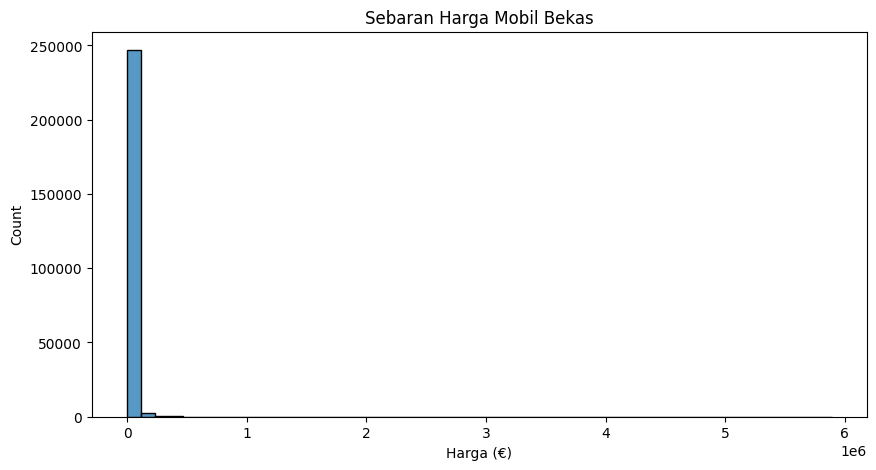

count    250880.00
mean      26137.53
std       36987.95
min         120.00
25%       11990.00
50%       19890.00
75%       29950.00
max     5890500.00
Name: price_in_euro, dtype: float64

In [290]:
pd.set_option('display.float_format', '{:.2f}'.format)

plt.figure(figsize=(10, 5))
sns.histplot(df_eda['price_in_euro'], bins=50)
plt.title('Sebaran Harga Mobil Bekas')
plt.xlabel('Harga (€)')
plt.show()

df_eda['price_in_euro'].describe()

Histogram menunjukkan bahwa sebaran sangat miring ke kanan (right-skewed), saya akan coba visualisasikan lebih jelas untuk harga umum di cell bawah

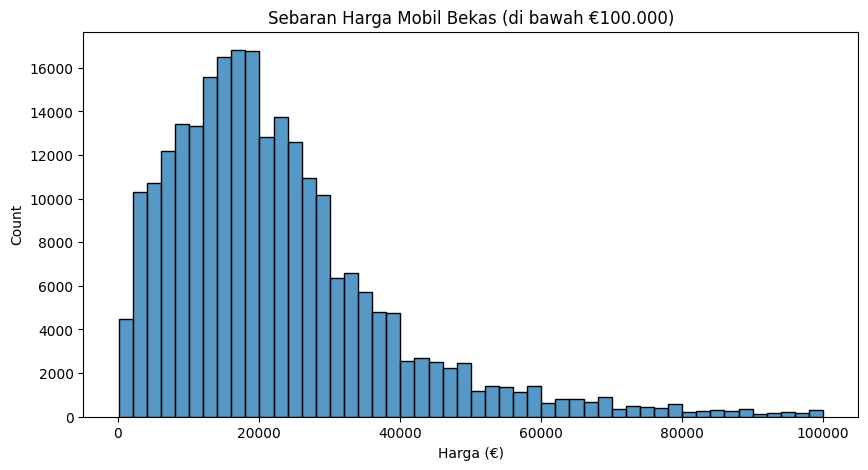

In [291]:
harga_umum = df_eda[df_eda['price_in_euro'] <= 100000]

plt.figure(figsize=(10, 5))
sns.histplot(harga_umum['price_in_euro'], bins=50)
plt.title('Sebaran Harga Mobil Bekas (di bawah €100.000)')
plt.xlabel('Harga (€)')
plt.show()

**Insights:**

Dari grafik histogram diats, terlihat bahwa sebaran harga mobil menunjukkan pola right skew

* Puncaknya di sekitar €15.000 sampai €20.000. Di rentang ini ada paling banyak mobil, sekitar 16 ribu iklan per batang.
* Sebagian besar mobil ada di rentang sekitar €5.000 sampai €30.000.
* Setelah €30.000 jumlahnya turun terus, dan makin ke kanan makin sedikit, tapi “ekornya” tetap panjang sampai €100.000.
* Bentuknya tetap miring ke kanan (right-skewed): banyak mobil murah sampai menengah, mobil mahal lebih sedikit
* Untuk penjual: harga mobil bekas di Jerman umumnya berkisar di €15 ribu sampai €20 ribu. Mobil di atas €40 ribu jauh lebih jarang.
* Untuk model: sebaran yang miring seperti ini bisa membuat prediksi model kurang akurat di mobil mahal, karena contohnya sedikit. Ini bisa jadi alasan nanti mencoba log transform pada harga di Feature Engineering.
* Soal outlier: harga di atas €100 ribu, sampai hampir €5,9 juta, perlu dicek di Feature Engineering: memang mobil mewah, atau salah input.

**Kesimpulan untuk penjual:** Penjual bisa melihat sebaran harga data mobil berdasarkan rentang harga masing masing sebaran.

## 4.2 Bagaimana harga mobil berdasarkan tahunnya?

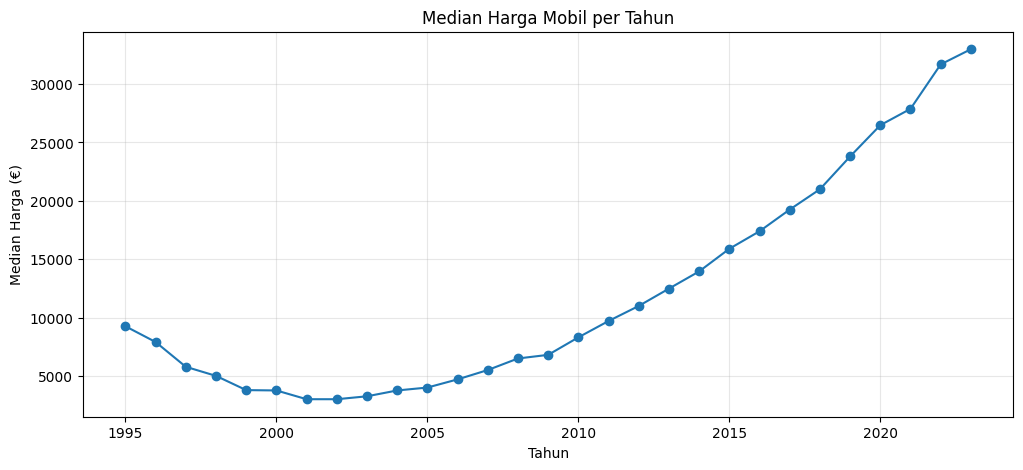

In [292]:
# visualisasi line chart harga mobil berdasarkan tahun
harga_per_tahun = df_clean.groupby('year')['price_in_euro'].median()

plt.figure(figsize=(12, 5))
harga_per_tahun.plot(marker='o')
plt.title('Median Harga Mobil per Tahun')
plt.xlabel('Tahun')
plt.ylabel('Median Harga (€)')
plt.grid(alpha=0.3)
plt.show()

**Insights:**

Dari line chart di atas, terlihat bahwa harga mobil bekas berdasarkan tahunnya membentuk pola seperti huruf **"U"**:

- **Mobil tahun 1995 sampai 1999** harganya justru lebih mahal dibanding mobil tahun 2000-an awal. Contohnya, median harga mobil tahun 1995 sekitar €9.000, sedangkan mobil tahun 2001-2002 hanya sekitar €3.000. Hal ini kemungkinan karena mobil-mobil lama tersebut sudah mulai dianggap **mobil klasik**, langka, atau termasuk mobil yang cukup mewah di zamannya, sehingga harganya naik lagi.
- **Mobil tahun 2001-2002** adalah yang **paling murah** (median sekitar €3.000). Mobil di umur ini sudah tua, tapi belum cukup tua untuk dianggap mobil klasik.
- **Mulai tahun 2002 sampai 2023, harga terus naik.** Semakin baru tahun mobilnya, semakin mahal harganya. Contohnya, median mobil tahun 2010 sekitar €8.000, tahun 2015 sekitar €16.000, dan tahun 2023 sekitar €33.000.
- Kenaikan harga paling tajam terjadi di **mobil tahun 2015 ke atas**, artinya mobil yang masih muda umurnya jauh lebih mahal dibanding mobil yang umurnya sudah lebih dari 10 tahun.

**Kesimpulan untuk penjual:** tahun mobil sangat berpengaruh terhadap harga. Mobil yang masih baru bisa dijual jauh lebih mahal, sedangkan mobil umur sekitar 20 tahun harganya sudah sangat turun. Tapi untuk mobil yang sangat tua, harganya bisa naik lagi apabila mobil tersebut tergolong klasik atau langka.

## 4.3 Apakah Odometer (Mileage) memengaruhi harga?

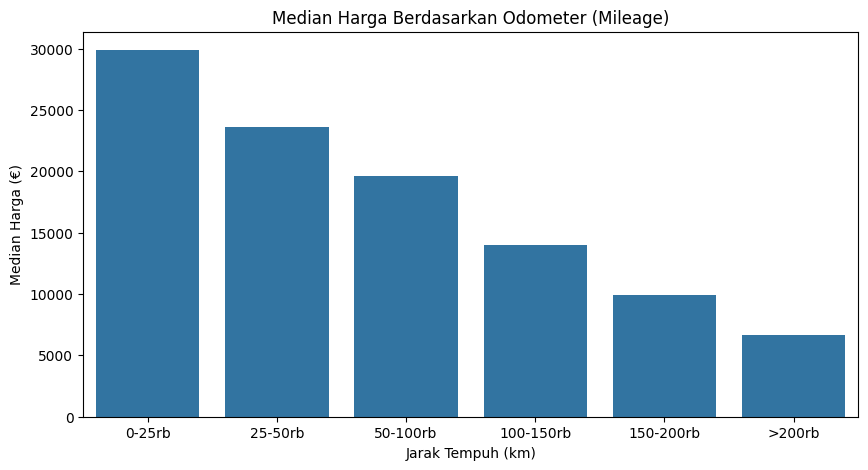

In [293]:
# mengelompokkan mileage dari 0-25 rb km -> lebih dari 200rb km odo nya
kelompok_km = pd.cut(df_eda['mileage_in_km'],
                     bins=[0, 25000, 50000, 100000, 150000, 200000, float('inf')],
                     labels=['0-25rb', '25-50rb', '50-100rb', '100-150rb', '150-200rb', '>200rb'],
                     include_lowest=True)

# median harga di setiap rentang
harga_per_km = df_eda.groupby(kelompok_km, observed=True)['price_in_euro'].median()

plt.figure(figsize=(10, 5))
sns.barplot(x=harga_per_km.index, y=harga_per_km.values)
plt.title('Median Harga Berdasarkan Odometer (Mileage)')
plt.xlabel('Jarak Tempuh (km)')
plt.ylabel('Median Harga (€)')
plt.show()



**Insight:**

Sesuai dengan domain knowledge, **semakin jauh jarak tempuh (odometer) mobil, semakin murah harganya**. Polanya terlihat jelas dan turun terus di setiap kelompok:

- Mobil dengan jarak tempuh **0-25 ribu km** paling mahal, dengan median harga sekitar **€30.000**.
- Di **25-50 ribu km**, median harganya turun ke sekitar **€23.500**.
- Di **50-100 ribu km**, sekitar **€19.500**.
- Di **100-150 ribu km**, sekitar **€14.000**.
- Di **150-200 ribu km**, sekitar **€10.000**.
- Mobil dengan jarak tempuh **di atas 200 ribu km** paling murah, dengan median sekitar **€6.500**, atau kurang dari seperempat harga mobil yang jarak tempuhnya masih di bawah 25 ribu km.

Penurunan harga paling terasa di **pemakaian odo rendah**. Dari kelompok 0-25 ribu km ke 25-50 ribu km saja, median harganya sudah turun sekitar €6.500, padahal jarak tempuhnya cuma bertambah 25 ribu km.

**Catatan:** jarak tempuh biasanya berhubungan dengan umur mobil. Mobil yang lebih tua cenderung sudah jalan lebih jauh. Jadi turunnya harga di grafik ini kemungkinan juga dipengaruhi oleh umur mobil, bukan hanya jarak tempuhnya saja.

**Kesimpulan untuk penjual:** jarak tempuh adalah salah satu faktor penting dalam menentukan harga. Mobil dengan odometer rendah bisa dijual jauh lebih mahal dibanding mobil yang sudah jalan ratusan ribu km.

## 4.4 Apakah mobil mewah tetap mahal walaupun odometer (mileage) sudah jauh?

In [294]:
# mengelompokkan merek mobil mewah
merek_mewah = ['porsche', 'ferrari', 'lamborghini', 'bentley', 'rolls-royce',
               'maserati', 'aston-martin', 'mclaren']

# klasifikasi mobil biasa dan mobil mewah
df_eda['kategori'] = 'Biasa'
df_eda.loc[df_eda['brand'].isin(merek_mewah), 'kategori'] = 'Mewah'

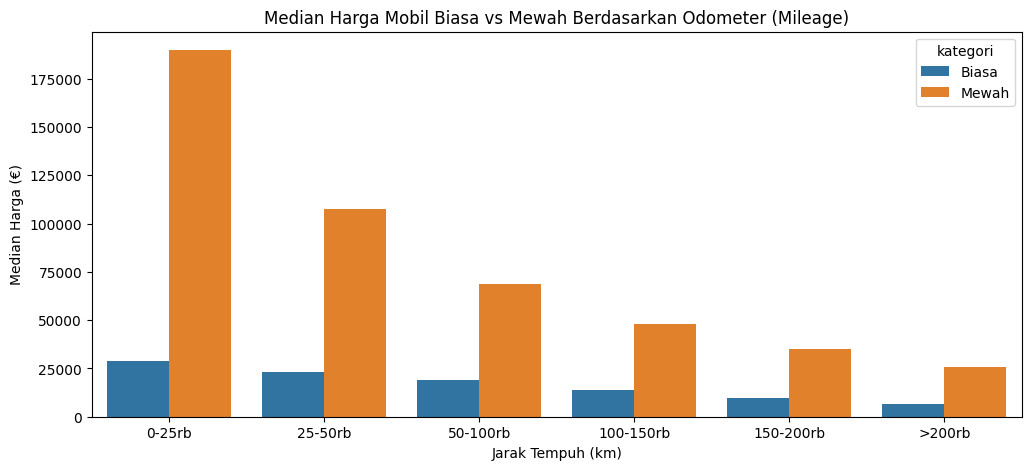

In [295]:
# mengelompokkan mileage dari 25rb sampai >200rb
df_eda['kelompok_km'] = pd.cut(df_eda['mileage_in_km'],
                               bins=[0, 25000, 50000, 100000, 150000, 200000, float('inf')],
                               labels=['0-25rb', '25-50rb', '50-100rb', '100-150rb', '150-200rb', '>200rb'],
                               include_lowest=True)

# median harga per kelompok jarak tempuh dan per kategori
harga_perbandingan = df_eda.groupby(['kelompok_km', 'kategori'], observed=True)['price_in_euro'].median().reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=harga_perbandingan, x='kelompok_km', y='price_in_euro', hue='kategori')
plt.title('Median Harga Mobil Biasa vs Mewah Berdasarkan Odometer (Mileage)')
plt.xlabel('Jarak Tempuh (km)')
plt.ylabel('Median Harga (€)')
plt.show()

**Insights:**

Mobil Mewah dikelompokkan berdasarkan `'porsche' 'ferrari', 'lamborghini', 'bentley', 'rolls-royce',
               'maserati', 'aston-martin', 'mclaren'`
               
Sedangkan mobil biasa dikelompokkan selain dari mobil mewah tersebut

Terbukti bahwa **mobil mewah tetap mahal walaupun odometer (mileage) sudah jauh**.

- Di **setiap kelompok odometer (mileage)**, median harga mobil mewah selalu jauh lebih mahal dibanding mobil biasa.
- Mobil mewah yang sudah jalan **lebih dari 200 ribu km** median harganya masih sekitar **€26.000**. Harga ini **hampir sama** dengan mobil biasa yang jarak tempuhnya masih **0-25 ribu km** (sekitar €29.000), dan lebih mahal dari mobil biasa dengan jarak tempuh 25-50 ribu km (sekitar €23.000).
- Di jarak tempuh yang sama, misalnya di atas 200 ribu km, mobil mewah sekitar **4 kali lebih mahal** dibanding mobil biasa (sekitar €26.000 vs €6.500).

Tapi ada hal menarik: **harga mobil mewah turunnya jauh lebih cepat**.

- Mobil mewah turun dari sekitar **€190.000** (0-25 ribu km) ke sekitar **€108.000** (25-50 ribu km). Artinya harganya turun hampir **setengah** hanya dalam 25 ribu km pertama.
- Sedangkan mobil biasa di rentang yang sama hanya turun dari sekitar €29.000 ke €23.000

**Kesimpulan untuk penjual:** merek mobil sangat menentukan harga. Mobil mewah tetap bernilai tinggi walaupun sudah jalan jauh, tapi penurunan harganya di odo rendah sangat besar. Karena itu, model nanti perlu memakai informasi merek (`brand`) supaya bisa membedakan harga mobil mewah dan mobil biasa.`

## 4.5 Jenis bahan bakar apa yang paling mahal?

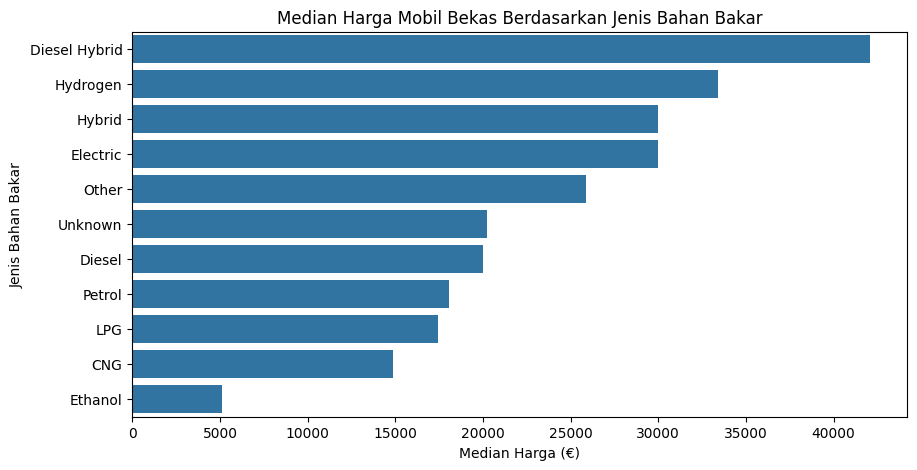

In [296]:
# Median harga per jenis bahan bakar, diurutkan dari yang paling mahal
harga_fuel_type = df_eda.groupby('fuel_type')['price_in_euro'].median().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=harga_fuel_type.values, y=harga_fuel_type.index)
plt.title('Median Harga Mobil Bekas Berdasarkan Jenis Bahan Bakar')
plt.xlabel('Median Harga (€)')
plt.ylabel('Jenis Bahan Bakar')
plt.show()

In [297]:
# sebaran data pada fuel_type
df_eda['fuel_type'].value_counts().drop_duplicates()

fuel_type
Petrol           143280
Diesel            86421
Hybrid            12607
Electric           5967
LPG                1255
CNG                 508
Diesel Hybrid       476
Other               178
Unknown              96
Hydrogen             82
Ethanol              10
Name: count, dtype: int64

**Insight:**

Dari bar chart di atas, terlihat bahwa jenis bahan bakar cukup berpengaruh ke harga mobil bekas:

- **Diesel Hybrid** paling mahal, dengan median harga sekitar **€42.000**. Kemungkinan karena mobil diesel hybrid biasanya mobil keluaran baru dan banyak dari merek premium.
- **Hydrogen** di posisi kedua, sekitar **€33.500**. Tapi datanya cuma **82 mobil**, jadi angka ini belum terlalu bisa dipercaya.
- **Hybrid** dan **Electric** harganya hampir sama, sekitar **€30.000**. Mobil-mobil ini biasanya masih baru, jadi wajar kalau harganya lebih mahal.
- **Diesel** (sekitar €20.000) dan **Petrol** (sekitar €18.000), yang jumlahnya paling banyak di data, justru harganya lebih murah dibanding mobil hybrid dan listrik.
- **LPG** (sekitar €17.500) dan **CNG** (sekitar €15.000) lebih murah lagi.
- **Ethanol** paling murah, sekitar **€5.000**. Tapi datanya cuma **10 mobil**, jadi sama seperti Hydrogen, angka ini belum bisa dijadikan patokan.

**Catatan:** kategori **Unknown** (sekitar €20.000) dan **Other** (sekitar €26.000) juga datanya sedikit, jadi tidak terlalu dibahas.

**Kesimpulan untuk penjual:** mobil hybrid dan listrik cenderung bisa dijual lebih mahal dibanding mobil bensin dan diesel biasa. Tapi ini juga kemungkinan karena mobil hybrid dan listrik umumnya masih baru, jadi bukan cuma karena jenis bahan bakarnya saja.

## 4.6 Harga berdasarkan jenis transmisi

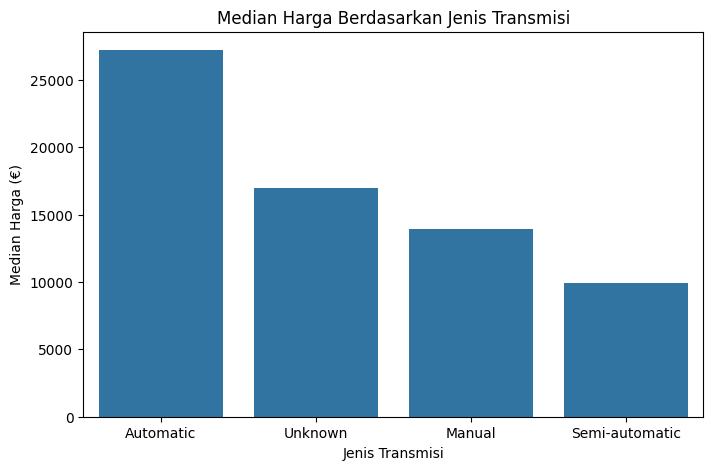

In [298]:
# Median harga per jenis transmisi, diurutkan dari yang paling mahal
harga_per_transmisi = df_eda.groupby('transmission_type')['price_in_euro'].median().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=harga_per_transmisi.index, y=harga_per_transmisi.values)
plt.title('Median Harga Berdasarkan Jenis Transmisi')
plt.xlabel('Jenis Transmisi')
plt.ylabel('Median Harga (€)')
plt.show()

In [299]:
df_eda['transmission_type'].value_counts().drop_duplicates()

transmission_type
Automatic         131640
Manual            117780
Unknown             1143
Semi-automatic       317
Name: count, dtype: int64

**Insight:**

Dari bar chart di atas, terlihat bahwa jenis transmisi cukup berpengaruh ke harga mobil bekas:

- **Automatic** paling mahal, dengan median harga sekitar **€27.000**. Harga ini hampir **2 kali lipat** dibanding mobil **Manual** (sekitar **€14.000**).
- **Manual** lebih murah, kemungkinan karena mobil manual banyak dipakai di mobil-mobil kecil dan mobil yang umurnya sudah lebih tua.
- **Semi-automatic** justru paling murah, sekitar **€10.000**. Tapi datanya cuma sekitar **300 mobil**, jadi angka ini belum terlalu bisa dijadikan patokan. Kemungkinan juga mobil semi-automatic di data ini kebanyakan mobil lama.
- **Unknown** (sekitar €17.000) artinya transmisinya tidak diisi penjual, jadi tidak terlalu dibahas.

**Catatan:** mahalnya mobil automatic kemungkinan juga dipengaruhi faktor lain. Mobil keluaran baru dan mobil merek premium sekarang kebanyakan sudah pakai transmisi automatic, jadi bukan cuma karena transmisinya saja.

**Kesimpulan untuk penjual:** mobil dengan transmisi automatic cenderung bisa dijual jauh lebih mahal dibanding mobil manual. Jenis transmisi bisa jadi salah satu informasi penting untuk model dalam menebak harga.

## 4.7 Merk mobil mana yang harganya stabil?

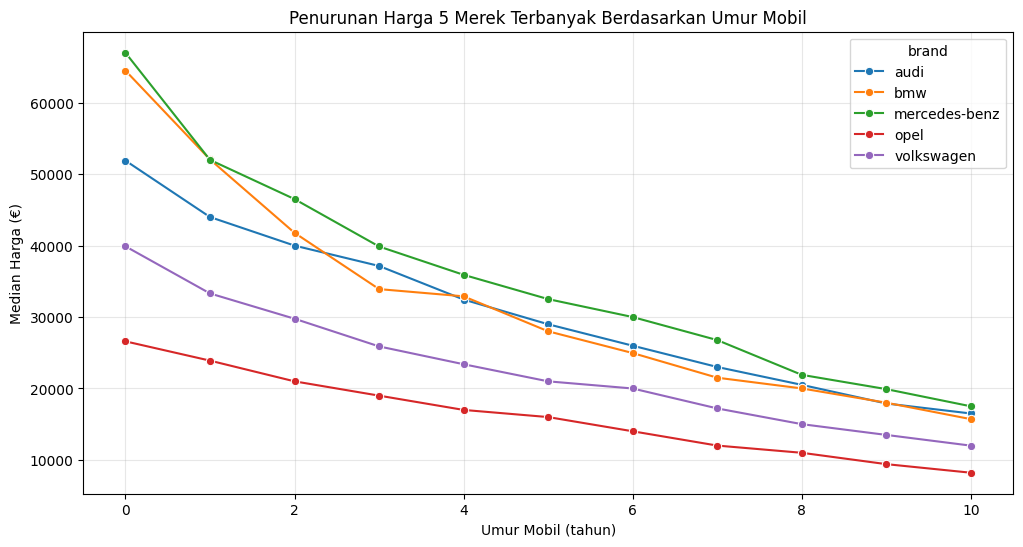

In [300]:
# Ambil 5 merek dengan iklan terbanyak, umur mobil maksimal 10 tahun
top5 = df_eda['brand'].value_counts().head(5).index
data_top5 = df_eda[(df_eda['brand'].isin(top5)) & (df_eda['age'] <= 10)]

# Median harga per umur dan per merek
harga_merek_umur = data_top5.groupby(['age', 'brand'])['price_in_euro'].median().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=harga_merek_umur, x='age', y='price_in_euro', hue='brand', marker='o')
plt.title('Penurunan Harga 5 Merek Terbanyak Berdasarkan Umur Mobil')
plt.xlabel('Umur Mobil (tahun)')
plt.ylabel('Median Harga (€)')
plt.grid(alpha=0.3)
plt.show()

In [301]:
data_top5['brand'].value_counts()

brand
volkswagen       21396
mercedes-benz    16805
audi             15606
opel             15438
bmw              12270
Name: count, dtype: int64

**Insight:**

Dari line chart di atas, terlihat bahwa **semua merek harganya turun seiring umur mobil**, tapi rate turunnya beda-beda:

- **Mercedes-Benz** paling mahal di hampir semua umur. Waktu masih baru (umur 0 tahun) median harganya sekitar **€67.000**, dan di umur 10 tahun masih sekitar **€17.500**.
- **BMW** awalnya hampir semahal Mercedes-Benz (sekitar **€64.500**), tapi harganya **turun paling cepat**. Cuma dalam 2 tahun, harganya sudah turun ke sekitar **€42.000**. Di umur 3-4 tahun, harga BMW sudah setara dengan Audi.
- **Audi** mulai dari sekitar **€52.000**, turunnya lebih pelan dibanding BMW dan Mercedes-Benz.
- **Volkswagen** mulai dari sekitar **€40.000** dan turun pelan-pelan ke sekitar **€12.000** di umur 10 tahun.
- **Opel** paling murah di semua umur, mulai dari sekitar **€26.500** sampai sekitar **€8.000** di umur 10 tahun.

Kalau dilihat dari **sisa harganya setelah 10 tahun**:
- Mercedes-Benz dan BMW cuma tersisa sekitar **seperempat** dari harga waktu baru.
- Audi, Volkswagen, dan Opel tersisa sekitar **sepertiga** dari harga waktu baru.

Artinya, **merek premium seperti Mercedes-Benz dan BMW memang lebih mahal, tapi persentase penurunan harganya lebih besar** dibanding merek biasa seperti Volkswagen dan Opel.

**Kesimpulan untuk penjual:** merek dan umur mobil sama-sama berpengaruh besar ke harga. Pemilik mobil premium seperti BMW perlu tahu bahwa harga mobilnya turun cukup cepat di 2 tahun pertama, sedangkan mobil merek biasa harganya turun lebih pelan dan stabil.

## 4.7 Apakah data dengan emisi 0 g/km itu mobil listrik?

In [302]:
df_eda[df_eda['fuel_consumption_g_km'] == 0]['fuel_type'].value_counts()

fuel_type
Petrol           3472
Electric         2930
Diesel           1706
Hybrid            266
LPG                62
Hydrogen           57
CNG                15
Other              12
Diesel Hybrid      12
Ethanol             1
Name: count, dtype: int64

**Insight:**

Awalnya diduga data dengan emisi **0 g/km** adalah mobil listrik. Tapi setelah dicek, ternyata **tidak semuanya mobil listrik**:

- Dari total **8.533** data dengan emisi 0 g/km, yang mobil listrik (**Electric**) cuma **2.930** data.
- Justru paling banyak mobil **Petrol** (3.472 data) dan **Diesel** (1.706 data), padahal mobil bensin dan diesel pasti mengeluarkan emisi.
- Ada juga Hybrid, LPG, CNG, Diesel Hybrid, Other, dan Ethanol dengan emisi 0.
- **Hydrogen** (57 data) wajar emisinya 0, karena mobil hidrogen juga tidak mengeluarkan CO2 dari knalpot.

Kemungkinan besar, data emisi mobil-mobil non-listrik ini **tidak diisi oleh penjual**, sehingga tercatat sebagai 0. Jadi angka 0 untuk mobil selain Electric dan Hydrogen **bukan emisi yang asli**, dan akan dianggap sebagai data kosong.

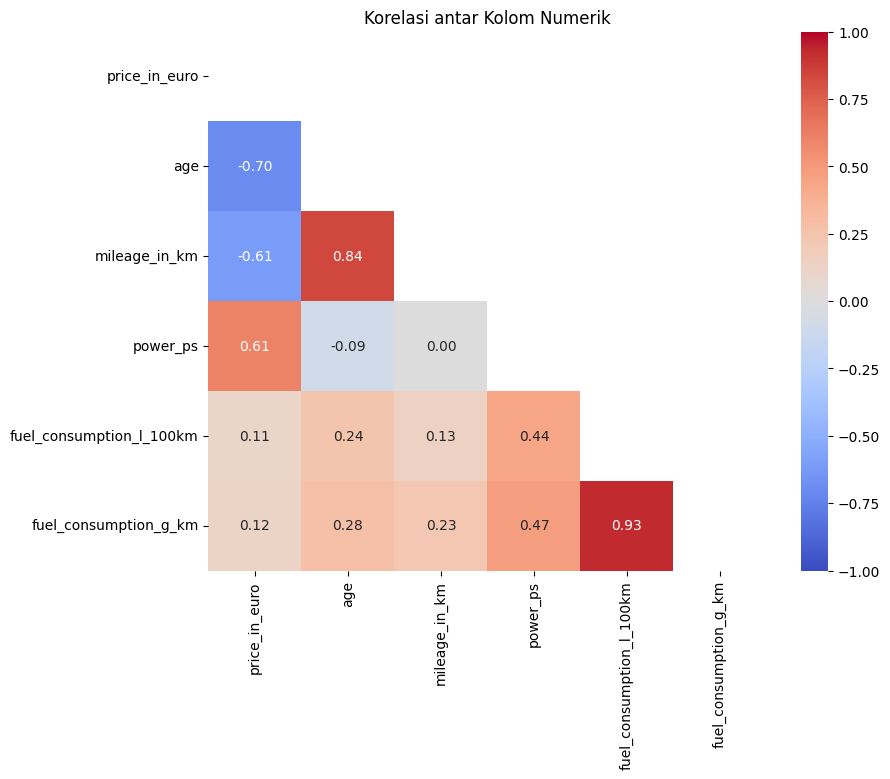

In [303]:
# visualisasi heatmap korelasi kolom numerik

kolom_korelasi = ['price_in_euro', 'age', 'mileage_in_km', 'power_ps',
                  'fuel_consumption_l_100km', 'fuel_consumption_g_km']

korelasi = df_eda[kolom_korelasi].corr(method='spearman')

# Tutupi segitiga atas (termasuk diagonal) supaya tidak dobel
mask = np.triu(np.ones_like(korelasi, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(korelasi, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Korelasi antar Kolom Numerik')
plt.show()

**Insight:**

Dari heatmap korelasi di atas, ada beberapa hal yang terlihat:

**Hubungan kolom angka dengan harga (`price_in_euro`):**
- **`age` (umur mobil)** paling berpengaruh, dengan korelasi **-0,70**. Tanda minus artinya **semakin tua mobilnya, semakin murah harganya**.
- **`mileage_in_km` (jarak tempuh)** korelasinya **-0,61**. Artinya **semakin jauh odo (Mileage), semakin murah harganya**.
- **`power_ps` (tenaga mesin)** korelasinya **0,61**. Artinya **semakin besar tenaga mesinnya, semakin mahal harganya**.
- **`fuel_consumption_l_100km`** (0,11) dan **`fuel_consumption_g_km`** (0,12) korelasinya **sangat kecil**, jadi konsumsi bahan bakar dan emisi hampir tidak berhubungan dengan harga.

**Hubungan antar kolom selain harga:**
- **`age` dan `mileage_in_km`** korelasinya **0,84** (tinggi). bisa dibilang wajar, karena mobil yang lebih tua biasanya sudah jalan lebih jauh.
- **`fuel_consumption_l_100km` dan `fuel_consumption_g_km`** korelasinya **0,93** (sangat tinggi). Ini karena semakin boros bensinnya, semakin banyak juga emisi CO2 yang keluar. Artinya dua kolom ini isinya hampir sama.

**Kesimpulan untuk model:**
- Kolom angka yang paling penting untuk menebak harga adalah **`age`**, **`mileage_in_km`**, dan **`power_ps`**.
- Karena `fuel_consumption_l_100km` dan `fuel_consumption_g_km` isinya hampir sama, saya akan **cukup memilih pakai salah satu** saja.

## 4.9 Cek nilai yang anomali

Di EDA kita lihat ada harga sampai hampir €5,9 juta dan ada harga €120. Sebelum ditindak, saya akan mengecek dulu jumlahnya:

In [304]:
# cek nilai anomali
df_clean[['price_in_euro', 'power_ps', 'mileage_in_km', 'age']].describe()

,price_in_euro,power_ps,mileage_in_km,age
count,250880.00,250752.00,250818.00,250880.00
mean,26137.53,171.69,85368.67,6.74
std,36987.95,97.89,78721.33,5.46
min,120.00,1.00,0.00,0.00
25%,11990.00,111.00,24950.00,3.00
50%,19890.00,150.00,67515.00,5.00
75%,29950.00,190.00,126538.50,10.00
max,5890500.00,999.00,3800000.00,28.00


In [305]:
print('Harga di bawah €500       :', (df_clean['price_in_euro'] < 500).sum())
print('Harga di atas €500.000    :', (df_clean['price_in_euro'] > 500000).sum())
print('Tenaga mesin 0 PS         :', (df_clean['power_ps'] == 0).sum())
print('Tenaga mesin di atas 1000 PS:', (df_clean['power_ps'] > 1000).sum())
print('Jarak tempuh di atas 1 juta km:', (df_clean['mileage_in_km'] > 1000000).sum())

Harga di bawah €500       : 103
Harga di atas €500.000    : 129
Tenaga mesin 0 PS         : 0
Tenaga mesin di atas 1000 PS: 0
Jarak tempuh di atas 1 juta km: 31


**Insights:**

**Gambaran umum dari `describe()`:**

- **Harga (`price_in_euro`)**: median sekitar **€19.890**, tapi rata-ratanya lebih tinggi (**€26.137**) karena ada mobil yang sangat mahal. Harga paling murah **€120** dan paling mahal **€5.890.500**.
- **Tenaga mesin (`power_ps`)**: median **150 PS**, wajar untuk mobil pada umumnya. Tapi ada yang cuma **1 PS**, padahal tidak ada mobil dengan tenaga sekecil itu. Tenaga paling besar **999 PS**, masih mungkin untuk mobil sport atau supercar.
- **Jarak tempuh (`mileage_in_km`)**: median sekitar **67.500 km**. Tapi ada yang sampai **3,8 juta km**, dan itu tidak masuk akal.
- **Umur mobil (`age`)**: dari **0 sampai 28 tahun**, dengan median **5 tahun**. Sudah sesuai setelah cleaning.
- Masih ada sedikit **data kosong** di `power_ps` dan `mileage_in_km`. Ini nanti diisi di Pipeline.

**Hasil pengecekan:**

- **Harga di bawah €500**: ada **103 data**. Terlalu murah untuk harga mobil, kemungkinan salah input, jadi **dibuang**.
- **Harga di atas €500.000**: ada **129 data**. Bisa jadi mobil supercar yang memang mahal, bisa juga salah input, jadi **dicek dulu** mobilnya apa saja.
- **Tenaga mesin 0 PS**: **tidak ada**.
- **Tenaga mesin di atas 1000 PS**: **tidak ada**.
- **Jarak tempuh di atas 1 juta km**: ada **31 data**. Hampir mustahil untuk mobil, jadi **dibuang**.
- Tenaga mesin yang sangat kecil (di bawah 40 PS) juga perlu **dicek dulu**, karena ada yang cuma 1 PS.

Semua data yang dibuang jumlahnya sangat kecil dibanding total sekitar 250 ribu data, jadi tidak akan memengaruhi hasil.

## Menyimpan data EDA yang sudah di clean agar bisa diload oleh streamlit

In [306]:
df_eda.to_csv('data_eda.csv',index=False)

## 4.10 Kesimpulan EDA

Dari semua analisis di atas, ini hal-hal penting yang didapat:

**1. Sebaran harga**
- Harga mobil bekas di Jerman umumnya ada di sekitar **€15.000 sampai €20.000**.
- Sebarannya **miring ke kanan** (right-skewed): banyak mobil murah sampai menengah, dan sedikit mobil yang sangat mahal (sampai hampir €5,9 juta).

**2. Umur mobil paling berpengaruh ke harga**
- Semakin tua mobilnya, semakin murah harganya (korelasi **-0,70**, paling kuat dibanding kolom angka lain).
- Tapi mobil yang sangat tua (tahun 1995-1999) harganya bisa naik lagi, kemungkinan karena sudah tergolong **mobil klasik**. Jadi hubungan tahun dan harga membentuk pola seperti **huruf "U"**, bukan garis lurus.

**3. Jarak tempuh dan tenaga mesin juga penting**
- Semakin jauh jarak tempuh, semakin murah harganya (korelasi **-0,61**). Mobil dengan jarak tempuh di atas 200 ribu km harganya kurang dari seperempat mobil yang jarak tempuhnya di bawah 25 ribu km.
- Semakin besar tenaga mesin, semakin mahal harganya (korelasi **0,61**).

**4. Merek sangat menentukan harga**
- Mobil **mewah** (Porsche, Ferrari, Lamborghini, dan lainnya) tetap mahal walaupun jarak tempuhnya sudah jauh, tapi harganya turun sangat cepat di awal pemakaian.
- Merek premium seperti **Mercedes-Benz** dan **BMW** lebih mahal, tapi persentase penurunan harganya lebih besar dibanding merek biasa seperti **Volkswagen** dan **Opel**.

**5. Bahan bakar dan transmisi**
- Mobil **hybrid** dan **listrik** cenderung lebih mahal dibanding mobil bensin dan diesel, kemungkinan karena umumnya masih baru.
- Mobil **automatic** median harganya hampir **2 kali lipat** mobil manual.

**6. Temuan soal kualitas data**
- Ada data emisi **0 g/km** di mobil bensin dan diesel, padahal tidak mungkin. Data ini dianggap **data kosong**, bukan emisi asli.
- Kolom `fuel_consumption_l_100km` dan `fuel_consumption_g_km` isinya hampir sama (korelasi **0,93**), dan hubungannya dengan harga sangat kecil.
- Ada sedikit data yang **tidak masuk akal**:
  - **103 data** dengan harga di bawah **€500**, terlalu murah untuk harga mobil.
  - **31 data** dengan jarak tempuh di atas **1 juta km**, bahkan ada yang sampai 3,8 juta km.
  - Ada mobil dengan tenaga mesin cuma **1 PS**, padahal tidak ada mobil dengan tenaga sekecil itu.
- Ada juga **129 data** dengan harga di atas **€500.000**. Data ini perlu dicek, karena bisa jadi memang mobil supercar yang mahal.
- Data yang tidak masuk akal ini jumlahnya sangat sedikit dibanding total sekitar 250 ribu data, dan akan **dibuang di tahap Feature Engineering**.

**Rencana untuk tahap berikutnya:**
- Kolom yang dipakai untuk model: **`age`**, **`mileage_in_km`**, **`power_ps`**, **`brand`**, **`model`**, **`transmission_type`**, **`fuel_type`**, dan salah satu kolom konsumsi bahan bakar.
- Karena harga miring ke kanan dan ada outlier, perlu dicek penanganan **outlier** dan kemungkinan **log transform** pada harga.
- **Membuang data yang tidak masuk akal** (harga di bawah €500 dan jarak tempuh di atas 1 juta km) sebelum data dipakai untuk model.
- Karena ada pola yang tidak lurus (seperti pola "U" pada tahun), model berbasis pohon seperti **Decision Tree** dan **Random Forest** kemungkinan lebih cocok dibanding model linear. Model linear hanya bisa menggambarkan hubungan berupa garis lurus (harga terus naik atau terus turun), sedangkan model pohon memecah data menjadi beberapa kelompok, sehingga bisa mengikuti pola yang turun dulu lalu naik.`

# 5. Feature Engineering

In [307]:
#copy data dari cleaning ke fe (feature engineering)

df_fe = df_clean.copy()

## 5.1 Cardinality Check

In [308]:
df_fe.describe(include='O').T

,count,unique,top,freq
brand,250880,47,volkswagen,33263
model,250880,1312,Volkswagen Golf,7586
color,250714,14,black,58686
transmission_type,250880,4,Automatic,131640
fuel_type,250880,11,Petrol,143280


Insights:

Terdapat 2 kolom yang memiliki `high_cardinality` yaitu:
* `brand` sebanyak `47` Unique Value
* `model` sebanyak `1308` Unique Value

Semua kolom ini akan di preprocessing dengan menggunakan One Hot Encoder

## 5.2 Hapus data anomali (Handling Outlier)

Walaupun Random Forest robust terhadap outlier, data di bawah ini tetap dibuang karena nilainya **tidak masuk akal** (kemungkinan salah input) atau **di luar cakupan model**, bukan sekadar outlier. Data yang salah tetap akan membuat model belajar pola yang salah, dan harga yang sangat ekstrem bisa menarik rata-rata tebakan Random Forest. Selain itu, model lain yang dibandingkan (Linear Regression, KNN, dan SVM) lebih sensitif terhadap nilai ekstrem.

In [309]:
# Buang harga yang terlalu murah dan terlalu mahal (diputuskan di EDA)
df_fe = df_fe[df_fe['price_in_euro'] >= 500]
df_fe = df_fe[df_fe['price_in_euro'] <= 500000]

# Buang jarak tempuh yang tidak masuk akal (data kosong tetap disimpan)
df_fe = df_fe[~(df_fe['mileage_in_km'] > 1000000)]

# Buang tenaga mesin yang tidak masuk akal (data kosong tetap disimpan)
df_fe = df_fe[~(df_fe['power_ps'] < 5)]

print('Jumlah data sekarang:', df_fe.shape)
print('Data yang terbuang  :', len(df_clean) - len(df_fe))

Jumlah data sekarang: (250616, 13)
Data yang terbuang  : 264


## 5.3 Splitting Data

In [310]:
# splitting num cols dan cat cols
num_cols = ['age', 'mileage_in_km', 'power_ps', 'fuel_consumption_l_100km']
cat_cols = ['brand', 'model', 'color', 'transmission_type', 'fuel_type']

# X = fitur, y = target
X = df_fe[cat_cols + num_cols]
y = df_fe['price_in_euro']

# pembagian data set train dan test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=129)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)


X_train: (200492, 9)
X_test : (50124, 9)


## 5.4 Pipeline Preprocessing 

**Alasan pemilihan preprocessing:**

- **SimpleImputer (median)** untuk kolom angka: median tidak ketarik outlier, jadi lebih mewakili nilai umumnya.
- **SimpleImputer (most_frequent)** untuk kolom kategori: kategori tidak bisa dihitung rata-ratanya, jadi diisi dengan yang paling sering muncul.
- **StandardScaler**: skala kolom angka beda jauh (jarak tempuh ratusan ribu, umur cuma 0-28). Scaling dibutuhkan oleh model **Linear Regression** dan **KNN** yang akan dibandingkan, supaya kolom dengan angka besar tidak dianggap lebih penting. Untuk model berbasis treed (Decision Tree, Random Forest, Boosting) scaling tidak berpengaruh, jadi aman dipakai untuk semua model.
- **OneHotEncoder**: kategori di data ini tidak punya urutan (bensin tidak "lebih besar" dari diesel), jadi tidak pakai Ordinal Encoder.
  - `min_frequency=50`: kategori yang muncul kurang dari 50 kali digabung jadi "lainnya", karena datanya terlalu sedikit untuk di train model.
  - `handle_unknown='infrequent_if_exist'`: kategori baru yang belum pernah dilihat saat training otomatis masuk ke "lainnya", jadi tidak error.

In [311]:
# cek missing value pada X_train
X_train.isna().sum()

brand                           0
model                           0
color                         134
transmission_type               0
fuel_type                       0
age                             0
mileage_in_km                  46
power_ps                      103
fuel_consumption_l_100km    23213
dtype: int64

In [312]:
# utuk kolom numerik akan diisi nilai kosong dengan median, lalu menyamakan skalanya
pipe_numerik = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# untuk kolom kategorikal akan diisi nilai kosong dengan nilai yang paling sering muncul,
# lalu ubah jadi angka dengan One-Hot Encoding
pipe_kategori = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50))
])

# menggabugkan kolom angka pakai pipe_numerik, kolom kategori pakai pipe_kategori
preprocessor = ColumnTransformer([
    ('numerik', pipe_numerik, num_cols),
    ('kategori', pipe_kategori, cat_cols)
])

In [313]:
# membandingkan hasil x_train_pipe dengan sebelum di pipe
X_train_pre = preprocessor.fit_transform(X_train)

print('Sebelum:', X_train.shape)
print('Sesudah:', X_train_pre.shape)

Sebelum: (200492, 9)
Sesudah: (200492, 615)


Setelah melewati Pipeline, jumlah kolom bertambah dari **9** menjadi **615**. Ini karena One-Hot Encoding mengubah setiap kategori menjadi kolom sendiri, terutama dari kolom `model` (ratusan jenis model mobil) dan `brand`. Jumlah baris tetap **200.492**, artinya tidak ada data yang hilang saat diproses.

# 6. Model Definition

## 6.1 Metrik Evaluasi

- **MAE (Mean Absolute Error)** sebagai **metrik utama**. MAE adalah rata-rata selisih antara harga prediksi dan harga asli, dalam satuan euro. Mudah dipahami penjual, contohnya "rata-rata prediksi model meleset sekitar €2.000". MAE juga tidak terlalu terpengaruh oleh outlier.
- **RMSE (Root Mean Squared Error)** sebagai metrik pendukung. RMSE memberi hukuman lebih besar untuk prediksi yang meleset jauh, jadi berguna untuk melihat apakah ada prediksi yang sangat salah.
- **R² (R-squared)** sebagai metrik pendukung. Menunjukkan seberapa besar variasi harga yang bisa dijelaskan oleh model, dari 0 sampai 1. Semakin mendekati 1, semakin bagus.

## 6.2 Model yang Digunakan

Ada 5 model yang akan dibandingkan:

- **Linear Regression**: model paling sederhana, dipakai sebagai **baseline** (patokan). Model lain harus lebih bagus dari ini.
- **KNN (K-Nearest Neighbors)**: menebak harga dari mobil-mobil yang paling mirip. Cocok dengan cara orang menaksir harga mobil bekas, yaitu membandingkan dengan mobil serupa.
- **SVM (Support Vector Machine)**: untuk regresi, yaitu **LinearSVR**. SVM mencari garis (atau bidang) yang bisa menebak harga dengan kesalahan sekecil mungkin, dan mengabaikan kesalahan kecil di dalam batas tertentu.
- **Decision Tree**: bisa menangkap pola yang tidak lurus, seperti pola "U" antara tahun dan harga yang ditemukan di EDA.
- **Random Forest**: gabungan banyak Decision Tree (bagging), biasanya lebih stabil dan tidak gampang overfitting dibanding satu Decision Tree.
- **Gradient Boosting**: gabungan banyak pohon kecil yang dibangun berurutan, setiap pohon baru belajar memperbaiki kesalahan pohon sebelumnya (boosting).

**Hyperparameter awal** pakai nilai bawaan (default) dulu, lalu model terbaik akan di-tuning di tahap `Hyperparameter Tuning`

In [314]:
# setiap model digabung dengan preprocessor dalam satu Pipeline
model_lr = Pipeline([('preprocessor', clone(preprocessor)),
                     ('model', LinearRegression())])

model_knn = Pipeline([('preprocessor', clone(preprocessor)),
                      ('model', KNeighborsRegressor(n_neighbors=5))])

model_svm = Pipeline([('preprocessor', clone(preprocessor)),
                      ('model', LinearSVR(max_iter=5000, random_state=129))])

model_dt = Pipeline([('preprocessor', clone(preprocessor)),
                     ('model', DecisionTreeRegressor(random_state=129))])

model_rf = Pipeline([('preprocessor', clone(preprocessor)),
                     ('model', RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=129))])

model_gb = Pipeline([('preprocessor', clone(preprocessor)),
                     ('model', GradientBoostingRegressor(random_state=129))])

# 7. Model Training

## 7.1 Mengambil Sample Data Train

In [315]:
# diambil 50.000 data dari data train untuk membandingkan model
X_train_sampel = X_train.sample(50000, random_state=129)
y_train_sampel = y_train.loc[X_train_sampel.index]

print(X_train_sampel.shape, y_train_sampel.shape)

(50000, 9) (50000,)


## 7.2 Membandingkan 6 Model dengan Cross Validation

Model dengan Cross Validation Score terbaik akan dipilih untuk dilakukan `Hyperparameter Tuning`

In [316]:
# daftar model yang akan dibandingkan
dict_model = {
    'Linear Regression': model_lr,
    'KNN': model_knn,
    'SVM': model_svm,
    'Decision Tree': model_dt,
    'Random Forest': model_rf,
    'Gradient Boosting': model_gb
}

# tempat menyimpan hasil cross validation setiap model
hasil_cv = {}

# cross validation 5 fold untuk setiap model, metrik MAE
for nama, model in dict_model.items():
    skor = cross_val_score(model, X_train_sampel, y_train_sampel,
                           cv=5, scoring='neg_mean_absolute_error')
    hasil_cv[nama] = -skor
    print(f'{nama}: MAE rata-rata = {(-skor).mean():.2f}, std = {(-skor).std():.2f}')

Linear Regression: MAE rata-rata = 7138.52, std = 60.65
KNN: MAE rata-rata = 4812.20, std = 63.51
SVM: MAE rata-rata = 7998.99, std = 97.34
Decision Tree: MAE rata-rata = 5327.40, std = 126.54
Random Forest: MAE rata-rata = 3926.03, std = 37.49
Gradient Boosting: MAE rata-rata = 4931.25, std = 85.69


In [317]:
# mengubah hasil cross validation menjadi tabel
ringkasan = []
for nama, skor in hasil_cv.items():
    ringkasan.append({'Model': nama,
                      'MAE Rata-rata': skor.mean(),
                      'Std': skor.std()})

# urutkan dari MAE paling kecil (paling bagus)
hasil_df = pd.DataFrame(ringkasan).sort_values('MAE Rata-rata')
hasil_df

,Model,MAE Rata-rata,Std
4,Random Forest,3926.03,37.49
1,KNN,4812.20,63.51
5,Gradient Boosting,4931.25,85.69
3,Decision Tree,5327.40,126.54
0,Linear Regression,7138.52,60.65
2,SVM,7998.99,97.34


**Insights:**

Dilihat dari skor metrik MAE diatas:

(Lebih Kecil kedua nilai Lebih Bagus)

* Linear Regression mendapatkan MAE rata - rata: `7138` dengan Standar Deviasi: `60.65`
* KNN mendapatkan MAE rata - rata: `4812` dengan Standar Deviasi: `63.51`
* SVM Regression mendapatkan MAE rata - rata: `7998` dengan Standar Deviasi: `97.34`
* Decision Tree Regressor mendapatkan MAE rata - rata: `5327` dengan Standar Deviasi: `126.54`
* **Random Forest Regressor mendapatkan MAE rata - rata: `3926.03`, dengan Standar Deviasi: `37.49`**
* Gradient Boosting Regressor mendapatkan MAE rata - rata: `4931`, dengan Standar Deviasi: `85.69`

**Random Forest** akan dipilih karena mendapatkan `cross_val_score` dengan metrik `MAE`: `3926` dan Standar Deviasi `37.49` (Paling Kecil)

**Random Forest** akan dilanjutkan di tahap `HyperParameter Tuning`

## 7.3 Training Model RF Before Tuning

In [318]:
# trainning random forest sebelum tuning
model_rf.fit(X_train_sampel, y_train_sampel)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerik',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'mileage_in_km',
                                                   'power_ps',
                                                   'fuel_consumption_l_100km']),
                                                 ('kategori',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=50))]),
                                                  ['brand', 'model', 'color',
                                                   'transmission_type',
                                                   'fuel_type'])])),
                ('model', RandomForestRegressor(n_jobs=-1, random_state=129))])

## 7.4 Hyperparameter Tuning Model RF

In [319]:
# pilihan hyperparameter yang akan dicoba
param_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': [1.0, 0.5, 'sqrt']
}

tuning_rf = RandomizedSearchCV(model_rf,
                               param_distributions=param_rf,
                               n_iter=10,
                               cv=3,
                               scoring='neg_mean_absolute_error',
                               random_state=42,
                               verbose=1)

tuning_rf.fit(X_train_sampel, y_train_sampel)

print('Hyperparameter terbaik:', tuning_rf.best_params_)
print('MAE terbaik           :', -tuning_rf.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Hyperparameter terbaik: {'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 30}
MAE terbaik           : 3904.9636470357113


### 7.4.1 Eksperimen Training menggunakan Log Transform

In [320]:
# membandingkan random forest hasil tuning dengan menambahkan log transform pada harga
model_rf_log = TransformedTargetRegressor(
    regressor=clone(tuning_rf.best_estimator_),   
    func=np.log1p,                                 
    inverse_func=np.expm1                         
)

# train model di sampel yang sama supaya fair dibandingkan dengan model hasil tuning
model_rf_log.fit(X_train_sampel, y_train_sampel)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('numerik',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('scaler',
                                                                                                        StandardScaler())]),
                                                                                       ['age',
                                                                                        'mileage_in_km',
                                                                                        'power_ps',
                                                                                        'fuel_consumption_l_100km']),
                                                                                      ('kategori',
                                                                                       Pipeline(steps=[('imputer',
                                                                                                        SimpleImputer(strategy='most_frequent')),
                                                                                                       ('encoder',
                                                                                                        OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                                                      min_frequency=50))]),
                                                                                       ['brand',
                                                                                        'model',
                                                                                        'color',
                                                                                        'transmission_type',
                                                                                        'fuel_type'])])),
                                                     ('model',
                                                      RandomForestRegressor(max_depth=30,
                                                                            max_features=0.5,
                                                                            min_samples_split=5,
                                                                            n_jobs=-1,
                                                                            random_state=129))]))

## 7.5 Training Model Final (Best Model Training)

In [321]:
# cek best hyperparameters
tuning_rf.best_params_

{'model__n_estimators': 100,
 'model__min_samples_split': 5,
 'model__min_samples_leaf': 1,
 'model__max_features': 0.5,
 'model__max_depth': 30}

In [322]:
# copy model hasil tuning lalu train
model_final = clone(tuning_rf.best_estimator_)
model_final.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerik',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'mileage_in_km',
                                                   'power_ps',
                                                   'fuel_consumption_l_100km']),
                                                 ('kategori',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=50))]),
                                                  ['brand', 'model', 'color',
                                                   'transmission_type',
                                                   'fuel_type'])])),
                ('model',
                 RandomForestRegressor(max_depth=30, max_features=0.5,
                                       min_samples_split=5, n_jobs=-1,
                                       random_state=129))])

# 8. Model Evaluation

## 8.1 Perbandingan Hasil Cross Validation Semua Model

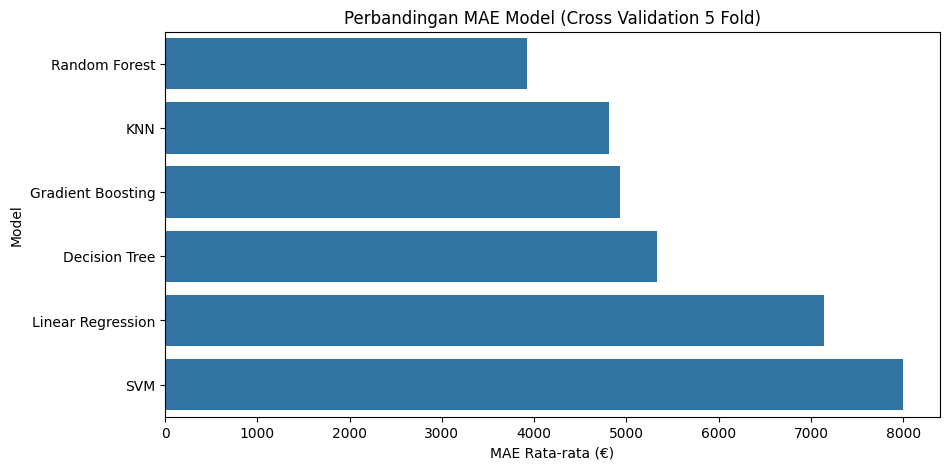

In [323]:
# visualisasi perbandingan MAE Cross Validation semua model
plt.figure(figsize=(10, 5))
sns.barplot(data=hasil_df, x='MAE Rata-rata', y='Model')
plt.title('Perbandingan MAE Model (Cross Validation 5 Fold)')
plt.xlabel('MAE Rata-rata (€)')
plt.ylabel('Model')
plt.show()

**Analisis:**

- **Random Forest** punya **MAE paling kecil** (sekitar **€3.900**) dan **std paling kecil** (sekitar **€37.49**). Artinya Random Forest paling akurat sekaligus paling stabil di setiap fold cross validation.
- Dibanding baseline **Linear Regression** (MAE sekitar €7.100), kesalahan Random Forest turun hampir **setengahnya**. Bisa dibilang sesuai dengan temuan di EDA bahwa hubungan fitur dengan harga **tidak lurus** (contohnya pola "U" pada tahun), sehingga model linear kurang cocok.
- **KNN** dan **Gradient Boosting** ada di urutan berikutnya, sedangkan **Decision Tree** paling tidak stabil (std paling besar) karena satu pohon gampang overfitting.
- **SVM (LinearSVR)** termasuk model linear, jadi sama seperti Linear Regression, kurang bisa menangkap pola yang tidak lurus. *MAE* menunjukkan nilai sekitar €8000

Karena itu, **Random Forest** dipilih untuk dilanjutkan ke tahap hyperparameter tuning sebelumnya.

## 8.2 Evaluasi Model RF Sebelum Tuning, Sesudah Tuning, Log Transform, Good Fit

### 8.2.1 Analisis Random Forest Sebelum Tuning

In [324]:
# membandingkan harga asli dan harga prediksi pada model rf sebelum mtuning dan menggunakna keseluruhan data 

perbandingan_awal = pd.DataFrame({
    'Harga Asli': y_test,
    'Harga Prediksi': model_rf.predict(X_test)
})
perbandingan_awal['Selisih'] = perbandingan_awal['Harga Asli'] - perbandingan_awal['Harga Prediksi']

perbandingan_awal.head(10)

,Harga Asli,Harga Prediksi,Selisih
113986,258000.00,222577.20,35422.80
149888,13500.00,15039.80,-1539.80
209534,27630.00,30814.87,-3184.87
164306,25200.00,22477.57,2722.43
61041,9950.00,12071.81,-2121.81
72884,44850.00,23615.29,21234.71
216562,4695.00,2480.71,2214.29
133757,11790.00,14006.90,-2216.90
18857,33590.00,34690.61,-1100.61
134084,29480.00,29692.49,-212.49


In [325]:
# menghitung MAE, RMSE, dan R2 model RF sebelum tuning di data train (sampel) dan data test
hasil_awal = pd.DataFrame({
    'Data': ['Train', 'Test'],
    'MAE': [mean_absolute_error(y_train_sampel, model_rf.predict(X_train_sampel)),
            mean_absolute_error(y_test, model_rf.predict(X_test))],
    'RMSE': [np.sqrt(mean_squared_error(y_train_sampel, model_rf.predict(X_train_sampel))),
             np.sqrt(mean_squared_error(y_test, model_rf.predict(X_test)))],
    'R2': [r2_score(y_train_sampel, model_rf.predict(X_train_sampel)),
           r2_score(y_test, model_rf.predict(X_test))]
})

hasil_awal

,Data,MAE,RMSE,R2
0,Train,1432.38,3692.45,0.98
1,Test,3781.79,9628.21,0.89


**Analisis Random Forest Sebelum Tuning:**

- Di data test, rata-rata prediksi model meleset sekitar **€3.781** (MAE), dan model bisa menjelaskan **89%** variasi harga (R² 0,89). Untuk model tanpa tuning, hasil ini sudah cukup bagus.
- Tapi model mengalami **overfitting**. Di data train, MAE-nya cuma **€1.432** dan R²-nya **0,98**, jauh lebih bagus dibanding di data test. Artinya model terlalu "hafal" data train, sehingga di data baru kesalahannya hampir 3 kali lebih besar.
- **RMSE test (€9.628) jauh lebih besar dari MAE test (€3.781).** Ini menunjukkan ada beberapa prediksi yang meleset sangat jauh, kemungkinan di mobil-mobil yang harganya mahal.
- Overfitting ini terjadi karena Random Forest default membiarkan setiap pohon tumbuh sedalam-dalamnya. Karena itu, perlu dilakukan **hyperparameter tuning** untuk mengurangi overfitting dan memperbaiki hasil di data test.

### 8.2.2 Analisis Random Forest Setelah Tuning

In [326]:
model_tuning = tuning_rf.best_estimator_

perbandingan_harga = pd.DataFrame({
    'Harga Asli': y_test,
    'Prediksi Sebelum Tuning': model_rf.predict(X_test),
    'Prediksi Sesudah Tuning': model_tuning.predict(X_test)
})

perbandingan_harga['Selisih Sebelum'] = perbandingan_harga['Harga Asli'] - perbandingan_harga['Prediksi Sebelum Tuning']
perbandingan_harga['Selisih Sesudah'] = perbandingan_harga['Harga Asli'] - perbandingan_harga['Prediksi Sesudah Tuning']

perbandingan_harga.head(10)

,Harga Asli,Prediksi Sebelum Tuning,Prediksi Sesudah Tuning,Selisih Sebelum,Selisih Sesudah
113986,258000.00,222577.20,216077.62,35422.80,41922.38
149888,13500.00,15039.80,15932.78,-1539.80,-2432.78
209534,27630.00,30814.87,30792.72,-3184.87,-3162.72
164306,25200.00,22477.57,24662.83,2722.43,537.17
61041,9950.00,12071.81,12766.83,-2121.81,-2816.83
72884,44850.00,23615.29,23331.44,21234.71,21518.56
216562,4695.00,2480.71,2572.92,2214.29,2122.08
133757,11790.00,14006.90,13563.61,-2216.90,-1773.61
18857,33590.00,34690.61,34505.85,-1100.61,-915.85
134084,29480.00,29692.49,30524.73,-212.49,-1044.73


In [327]:
# Model hasil tuning (sudah otomatis dilatih ulang di sampel yang sama)
model_tuning = tuning_rf.best_estimator_

hasil_tuning = pd.DataFrame({
    'Data': ['Train', 'Test'],
    'MAE': [mean_absolute_error(y_train_sampel, model_tuning.predict(X_train_sampel)),
            mean_absolute_error(y_test, model_tuning.predict(X_test))],
    'RMSE': [np.sqrt(mean_squared_error(y_train_sampel, model_tuning.predict(X_train_sampel))),
             np.sqrt(mean_squared_error(y_test, model_tuning.predict(X_test)))],
    'R2': [r2_score(y_train_sampel, model_tuning.predict(X_train_sampel)),
           r2_score(y_test, model_tuning.predict(X_test))]
})

hasil_tuning

,Data,MAE,RMSE,R2
0,Train,1949.79,4914.76,0.97
1,Test,3669.66,9256.63,0.90


In [328]:
perbandingan_tuning = pd.DataFrame({
    'Model': ['Sebelum Tuning', 'Sesudah Tuning'],
    'MAE Train': [hasil_awal['MAE'][0], hasil_tuning['MAE'][0]],
    'MAE Test': [hasil_awal['MAE'][1], hasil_tuning['MAE'][1]],
    'R2 Test': [hasil_awal['R2'][1], hasil_tuning['R2'][1]]
})

perbandingan_tuning

,Model,MAE Train,MAE Test,R2 Test
0,Sebelum Tuning,1432.38,3781.79,0.89
1,Sesudah Tuning,1949.79,3669.66,0.90


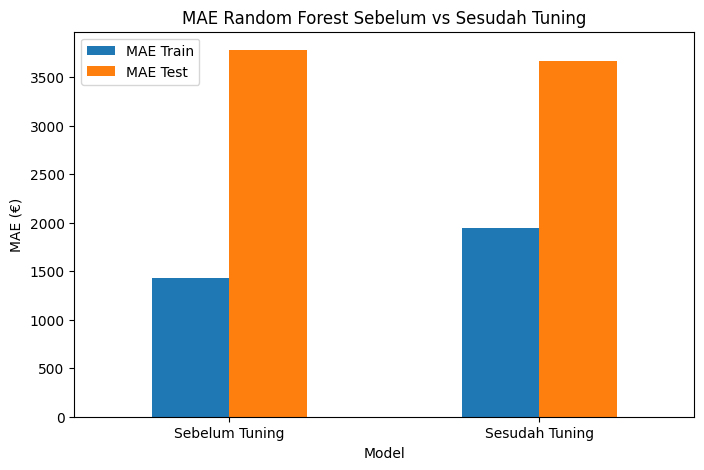

In [329]:
perbandingan_tuning.set_index('Model')[['MAE Train', 'MAE Test']].plot(kind='bar', figsize=(8, 5))
plt.title('MAE Random Forest Sebelum vs Sesudah Tuning')
plt.ylabel('MAE (€)')
plt.xticks(rotation=0)
plt.show()

**Analisis Sebelum vs Sesudah Tuning:**

- Setelah tuning, **MAE test turun** dari **€3.781** menjadi **€3.669**, dan **R² test naik** dari **0,89** menjadi **0,90**. RMSE test juga turun dari €9.658 menjadi €9.234. Artinya tebakan model di data baru jadi sedikit lebih akurat.
- **Overfitting berkurang.** Sebelum tuning, MAE test hampir **2,6 kali** MAE train. Setelah tuning, tinggal sekitar **1,9 kali**.
- **MAE train naik** dari €1.432 menjadi €1.949. Ini wajar, karena hyperparameter hasil tuning membuat model tidak terlalu menghafal data train, sehingga lebih bagus untuk data baru.
- Masih ada sedikit jarak antara hasil train dan test, tapi ini normal karena model biasanya selalu sedikit lebih bagus di data yang dipakai untuk belajar.

**Kesimpulan:** model **Random Forest sesudah tuning** dipilih sebagai model terbaik, karena lebih akurat di data test dan lebih tidak overfitting dibanding sebelum tuning.

### 8.2.3 Analisis Eksperimen Model Tuning + Log Transform pada Harga

**Analisis Eksperimen Log Transform:**

In [330]:
# evaluasi hasil model yang sudah log transform
hasil_log = pd.DataFrame({
    'Data': ['Train', 'Test'],
    'MAE': [mean_absolute_error(y_train_sampel, model_rf_log.predict(X_train_sampel)),
            mean_absolute_error(y_test, model_rf_log.predict(X_test))],
    'RMSE': [np.sqrt(mean_squared_error(y_train_sampel, model_rf_log.predict(X_train_sampel))),
             np.sqrt(mean_squared_error(y_test, model_rf_log.predict(X_test)))],
    'R2': [r2_score(y_train_sampel, model_rf_log.predict(X_train_sampel)),
           r2_score(y_test, model_rf_log.predict(X_test))]
})

hasil_log

,Data,MAE,RMSE,R2
0,Train,1954.12,5699.38,0.96
1,Test,3696.81,9902.17,0.89


In [331]:
# perbandingan tanpa log vs dengan log (sama-sama dilatih di sampel)
perbandingan_log = pd.DataFrame({
    'Model': ['RF Tuning (tanpa log)', 'RF Tuning (dengan log)'],
    'MAE Test': [hasil_tuning['MAE'][1], hasil_log['MAE'][1]],
    'RMSE Test': [hasil_tuning['RMSE'][1], hasil_log['RMSE'][1]],
    'R2 Test': [hasil_tuning['R2'][1], hasil_log['R2'][1]]
})

perbandingan_log

,Model,MAE Test,RMSE Test,R2 Test
0,RF Tuning (tanpa log),3669.66,9256.63,0.90
1,RF Tuning (dengan log),3696.81,9902.17,0.89


Log transform pada harga dicoba sebagai **model improvement**, dengan harapan model tidak terlalu terganggu oleh mobil-mobil yang sangat mahal. Kedua model sama-sama dilatih di sampel 50.000 data supaya perbandingannya adil.

- **MAE test sedikit naik** dari **€3.670** menjadi **€3.697** dibandingkan dengan model hasil tuning tanpa log
- **RMSE test naik** dari **€9.257** menjadi **€9.902**, dibandingkan dengan model hasil tuning tanpa log, yang artinya tebakan yang meleset jauh justru bertambah.
- **R² test turun** dari **0,90** menjadi **0,89**, dibandingkan dengan model hasil tuning tanpa log.

Jadi log transform **tidak memperbaiki** model. Kemungkinan penyebabnya, Random Forest menebak harga dengan rata-rata dari mobil-mobil yang mirip. Kalau dilatih dengan log, setelah dibalikkan ke euro hasilnya cenderung **lebih rendah**, terutama untuk mobil mahal. Padahal model sudah cenderung menebak terlalu murah untuk mobil mahal, sehingga log transform malah membuat kesalahannya lebih besar.

Karena itu, model final tetap memakai **Random Forest hasil tuning tanpa log transform**.

### 8.2.4 Analisis Model apakah sudah Good Fit?

**Apakah model sudah good fit?**


In [332]:
print('MAE cross validation:', -tuning_rf.best_score_)
print('MAE test            :', hasil_tuning['MAE'][1])

MAE cross validation: 3904.9636470357113
MAE test            : 3669.657009847473


- MAE cross validation: **€3.904**
- MAE test: **€3.669**

Kedua angka ini **sangat mirip**, artinya model **konsisten** saat menebak data yang belum pernah dilihat. Jadi model Random Forest hasil tuning bisa dibilang sudah **good fit**.

## 8.3 Evaluasi Best Model

In [333]:
hasil_final = pd.DataFrame({
    'Data': ['Train', 'Test'],
    'MAE': [mean_absolute_error(y_train, model_final.predict(X_train)),
            mean_absolute_error(y_test, model_final.predict(X_test))],
    'RMSE': [np.sqrt(mean_squared_error(y_train, model_final.predict(X_train))),
             np.sqrt(mean_squared_error(y_test, model_final.predict(X_test)))],
    'R2': [r2_score(y_train, model_final.predict(X_train)),
           r2_score(y_test, model_final.predict(X_test))]
})

hasil_final

,Data,MAE,RMSE,R2
0,Train,1872.84,4419.46,0.98
1,Test,3131.01,7726.47,0.93


In [334]:
perbandingan_final = pd.DataFrame({
    'Model': ['Sebelum Tuning', 'Sesudah Tuning', 'Model Final'],
    'MAE Train': [hasil_awal['MAE'][0], hasil_tuning['MAE'][0], hasil_final['MAE'][0]],
    'MAE Test': [hasil_awal['MAE'][1], hasil_tuning['MAE'][1], hasil_final['MAE'][1]],
    'R2 Test': [hasil_awal['R2'][1], hasil_tuning['R2'][1], hasil_final['R2'][1]]
})

perbandingan_final

,Model,MAE Train,MAE Test,R2 Test
0,Sebelum Tuning,1432.38,3781.79,0.89
1,Sesudah Tuning,1949.79,3669.66,0.90
2,Model Final,1872.84,3131.01,0.93


In [335]:
prediksi_final = pd.DataFrame({
    'Harga Asli': y_test,
    'Sebelum Tuning': model_rf.predict(X_test),
    'Sesudah Tuning': model_tuning.predict(X_test),
    'Harga di Log': model_rf_log.predict(X_test),
    'Model Final': model_final.predict(X_test)
    
})

prediksi_final['Selisih Model Final'] = prediksi_final['Harga Asli'] - prediksi_final['Model Final']

prediksi_final.head(10)

,Harga Asli,Sebelum Tuning,Sesudah Tuning,Harga di Log,Model Final,Selisih Model Final
113986,258000.00,222577.20,216077.62,199797.11,262859.18,-4859.18
149888,13500.00,15039.80,15932.78,15957.29,16746.51,-3246.51
209534,27630.00,30814.87,30792.72,30121.35,30412.96,-2782.96
164306,25200.00,22477.57,24662.83,24634.24,26067.86,-867.86
61041,9950.00,12071.81,12766.83,12706.31,11254.61,-1304.61
72884,44850.00,23615.29,23331.44,23001.48,21904.50,22945.50
216562,4695.00,2480.71,2572.92,2279.83,2789.38,1905.62
133757,11790.00,14006.90,13563.61,12704.71,12282.53,-492.53
18857,33590.00,34690.61,34505.85,34304.02,35638.48,-2048.48
134084,29480.00,29692.49,30524.73,29375.53,28742.26,737.74


**Analisis Perbandingan 5 Model:**

- **Model Final** punya hasil paling bagus di data test: **MAE €3.131** dan **R² 0,93**, lebih bagus dibanding model sebelum tuning (MAE €3.785) dan sesudah tuning dengan sampel (MAE €3.669).
- Bagaimanapun model sesudah tuning dan menggunakan log transform pada harga, tidak membuat prediksi model menjadi lebih baik
- Peningkatan terbesar datang dari **menambah data train** (dari 50 ribu jadi sekitar 200 ribu data), bukan hanya dari tuning.


**Contoh prediksi harga di data test:**

- Untuk mobil mahal seharga **€258.000**, Model Final menebak **€262.859**, cuma meleset sekitar **€6.500**. Sebelumnya, model sebelum dan sesudah tuning meleset sekitar €23.000 sampai €28.000. Artinya model final jauh lebih bagus untuk mobil mahal.
- Sebagian besar tebakan Model Final meleset cuma sekitar **€300 sampai €3.000** dari harga asli.
- Tapi ada mobil seharga **€44.850** yang ditebak cuma sekitar **€21.904** oleh Model Final, dan ketiga model sama-sama menebak sekitar €21.000 sampai €24.000. Kemungkinan harga mobil ini dipengaruhi hal yang **tidak ada di data**, seperti kondisi mobil, varian, atau kelengkapan fitur.
- Model Final tidak selalu lebih tepat di setiap mobil. Untuk beberapa mobil, tebakan model lain justru lebih dekat. Tapi **secara keseluruhan**, Model Final paling akurat, terlihat dari MAE dan R²-nya.

**Kesimpulan:** Model Final (Random Forest hasil tuning yang dilatih di seluruh data train) dipilih sebagai **model terbaik** untuk disimpan dan dipakai di inference dan deployment.

## 8.4 Visualisasi Harga Asli dan Prediksi Model Final

In [336]:
hasil_test = pd.DataFrame({
    'Harga Asli': y_test,
    'Prediksi': model_final.predict(X_test)
})
hasil_test['Selisih Absolut'] = (hasil_test['Harga Asli'] - hasil_test['Prediksi']).abs()

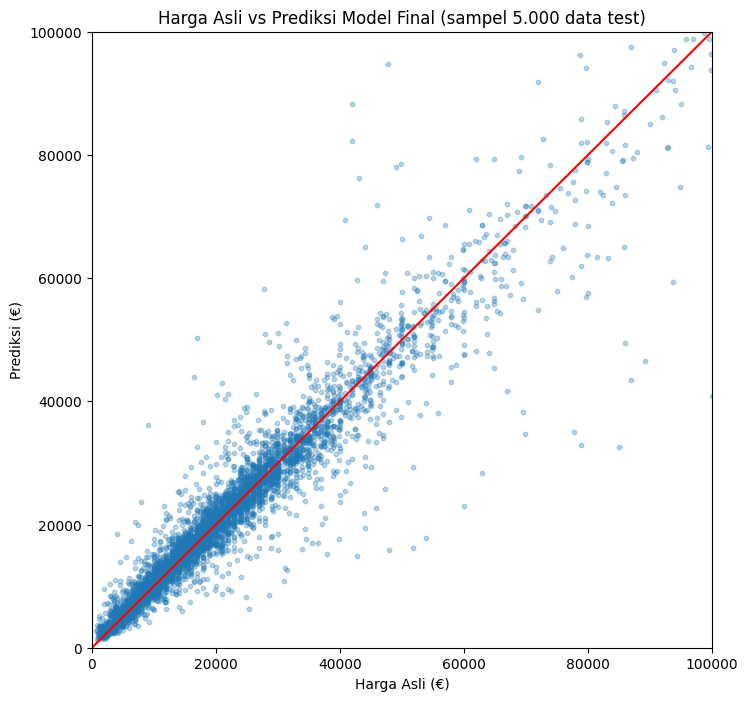

In [337]:
# ambil sampel 5.000 data supaya grafiknya tidak terlalu padat
sampel_plot = hasil_test.sample(5000, random_state=42)

plt.figure(figsize=(8, 8))
plt.scatter(sampel_plot['Harga Asli'], sampel_plot['Prediksi'], alpha=0.3, s=10)
plt.plot([0, 100000], [0, 100000], color='red')   # garis tebakan sempurna
plt.xlim(0, 100000)
plt.ylim(0, 100000)
plt.title('Harga Asli vs Prediksi Model Final (sampel 5.000 data test)')
plt.xlabel('Harga Asli (€)')
plt.ylabel('Prediksi (€)')
plt.show()

**Insight:**

Dari scatter plot di atas, terlihat bahwa sebagian besar titik **berkumpul rapat di sekitar garis merah** (garis tebakan sempurna). Artinya, secara umum tebakan model **sudah cukup dekat dengan harga aslinya**.

- Untuk mobil dengan harga **di bawah sekitar €30.000**, titik-titiknya sangat rapat di garis merah. Di rentang harga ini, yang juga paling banyak datanya, **model paling akurat**.
- Semakin mahal harga mobilnya, titik-titiknya **semakin menyebar** menjauhi garis merah. Artinya model **makin sering meleset** untuk mobil mahal.
- Untuk mobil mahal (sekitar €60.000 sampai €100.000), banyak titik yang ada **di bawah garis merah**, artinya model cenderung **menebak terlalu murah**. Contohnya ada mobil seharga sekitar €80.000 sampai €90.000 yang cuma ditebak sekitar €30.000 sampai €45.000.
- Ada juga beberapa mobil yang ditebak **terlalu mahal**, misalnya mobil seharga sekitar €42.000 yang ditebak hampir €90.000, tapi jumlahnya sedikit.

Hal ini sesuai dengan temuan di EDA: data mobil mahal **jauh lebih sedikit**, jadi model punya lebih sedikit contoh untuk belajar.

**Kesimpulan:** model sudah bagus untuk memberikan estimasi harga mobil bekas **pada umumnya** (harga menengah ke bawah), tapi kurang akurat untuk **mobil mahal**.

*DISCALIMER: grafik dibatasi sampai €100.000 supaya bagian yang paling banyak datanya terlihat jelas.*

## 8.5 Rata-rata Kesalahan Prediksi per Rentang Harga

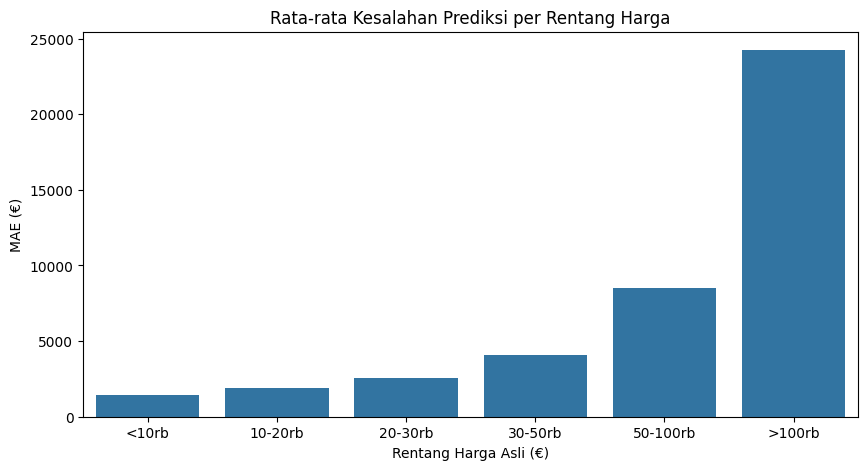

Kelompok Harga
<10rb       1436.66
10-20rb     1898.20
20-30rb     2529.63
30-50rb     4065.88
50-100rb    8507.36
>100rb     24244.55
Name: Selisih Absolut, dtype: float64

In [338]:
# mengelompokkan mobil berdasarkan harga aslinya
hasil_test['Kelompok Harga'] = pd.cut(hasil_test['Harga Asli'],
                                      bins=[0, 10000, 20000, 30000, 50000, 100000, 500000],
                                      labels=['<10rb', '10-20rb', '20-30rb', '30-50rb', '50-100rb', '>100rb'])

# rata-rata kesalahan (MAE) di setiap kelompok harga
mae_per_kelompok = hasil_test.groupby('Kelompok Harga', observed=True)['Selisih Absolut'].mean()

# visualisasi MAE per kelompok harga
plt.figure(figsize=(10, 5))
sns.barplot(x=mae_per_kelompok.index, y=mae_per_kelompok.values)
plt.title('Rata-rata Kesalahan Prediksi per Rentang Harga')
plt.xlabel('Rentang Harga Asli (€)')
plt.ylabel('MAE (€)')
plt.show()

# tampilkan angkanya
mae_per_kelompok

**Insight:**

Grafik di atas menunjukkan rata-rata kesalahan model di setiap rentang harga. Semakin mahal mobilnya, semakin besar kesalahan prediksi dalam euro. Ini sejalan dengan scatter plot sebelumnya: titik-titik untuk mobil mahal lebih menyebar dari garis merah.

Penyebabnya, data mobil mahal **jauh lebih sedikit** dibanding mobil murah sampai menengah (sesuai EDA 4.1), sehingga model punya lebih sedikit contoh untuk belajar.

## 8.6 Kelebihan, Kekurangan, dan Saran Improvement Model

**Kelebihan model:**
- **Cukup akurat untuk mobil pada umumnya.** Di data test, rata-rata kesalahan model sekitar **€3.135** (MAE) dengan R² **0,93**. Dengan median harga mobil sekitar €19.800, model ini sudah cukup untuk memberikan **estimasi harga acuan awal** bagi penjual, sesuai tujuan project.
- **Konsisten di data baru.** MAE cross validation dan MAE test mirip, artinya model tidak sekadar menghafal data train.
- **Mudah dipakai.** Preprocessing ada di dalam Pipeline, jadi penjual cukup memasukkan data mobil dalam format biasa (merek, model, tahun, jarak tempuh, dan seterusnya).
- **Bisa menangkap pola yang tidak lurus**, seperti pola "U" pada tahun mobil dan mobil mewah yang tetap mahal walaupun jarak tempuhnya jauh.

**Kekurangan model (kaitannya dengan bisnis):**
- **Kurang akurat untuk mobil mahal.** Kesalahan prediksi makin besar untuk mobil mahal, dan model cenderung menebak terlalu murah. Untuk dealer mobil premium atau mewah, estimasi model perlu dicek ulang secara manual.
- **Tidak bisa dipakai untuk mobil di atas €500.000**, karena data tersebut dibuang dari training.
- **Belum memperhitungkan kondisi mobil.** Model hanya melihat spesifikasi, tidak tahu kondisi fisik, varian, kelengkapan fitur, atau riwayat servis. Dua mobil dengan spesifikasi sama tapi kondisi berbeda akan diprediksi dengan harga yang sama.
- **Harga yang dipelajari adalah harga iklan tahun 2023 di Jerman**, bukan harga transaksi. Untuk pasar lain atau tahun yang berbeda, estimasinya bisa meleset.
- **Ukuran file model cukup besar** (sekitar 558 MB), sehingga butuh waktu lebih lama saat deployment.

**Saran improvement:**
- Memanfaatkan kolom **`offer_description`** untuk mengambil informasi tambahan, misalnya kata kunci fitur atau varian mobil.
- Mencoba **lebih banyak kombinasi hyperparameter** (menambah `n_iter`) atau algoritma boosting lain.
- Memperbarui data dengan iklan terbaru, supaya estimasi harga mengikuti kondisi pasar sekarang.

# 9. Model Saving

In [339]:
# save model final (Pipeline lengkap: preprocessing + Random Forest)
with open('model_final.pkl', 'wb') as file:
    pickle.dump(model_final, file)

# cek file size
ukuran = os.path.getsize('model_final.pkl') / (1024 * 1024)
print(f'file size model: {ukuran:.1f} MB')

file size model: 557.7 MB


# Conclusion:

Project ini bertujuan membangun **model machine learning (regresi)** untuk memberikan **estimasi harga pasaran mobil bekas sebagai acuan awal** bagi penjual, menggunakan data iklan mobil bekas di Jerman dari AutoScout24.

**Hasil EDA:**
- Harga mobil bekas umumnya ada di sekitar **€15.000 sampai €20.000**, dengan sebaran yang miring ke kanan.
- **Umur mobil**, **jarak tempuh**, dan **tenaga mesin** adalah kolom angka yang paling berpengaruh ke harga.
- **Merek** sangat menentukan harga: mobil mewah tetap mahal walaupun jarak tempuhnya jauh, sedangkan merek premium seperti Mercedes-Benz dan BMW harganya turun lebih cepat secara persentase.
- Mobil **automatic**, **hybrid**, dan **electric** cenderung lebih mahal.

**Hasil modeling:**
- Dari 6 model yang dibandingkan dengan cross validation, **Random Forest** memberikan hasil terbaik dan paling stabil.
- **Hyperparameter tuning** menurunkan MAE test dan mengurangi overfitting. Melatih ulang model hasil tuning di **seluruh data train** menurunkan MAE test lagi menjadi sekitar **€3.131**, dengan R² **0,93**.
- MAE cross validation dan MAE test mirip, sehingga model bisa dibilang **good fit**.
- Pada inference, hasil prediksi untuk mobil baru **sesuai dengan logika dan insight EDA**.

**Kesimpulan:** objective project **tercapai**. Model sudah bisa memberikan estimasi harga mobil bekas yang cukup akurat untuk mobil pada umumnya, sehingga bisa membantu penjual menentukan harga acuan awal sebelum memasang iklan. Namun, model masih kurang akurat untuk mobil mahal dan belum memperhitungkan kondisi fisik mobil, sehingga hasil estimasi tetap perlu disesuaikan dengan kondisi mobil yang sebenarnya.

## Model inference dilakukan di notebook P1M2_rizqi_utama_inf.ipynb menggunakan model model_final.pkl.